# CASMI 2026: A Complete Statistical Tour of the Data

**Task.** Given the tandem mass spectra (MS/MS) of an unknown small molecule, predict its
2-D structure. You submit up to **25 SMILES per molecule**, best guess first, and are scored
by **MRR@25** -- a hit at rank 1 is worth 1.0, at rank 2 is worth 0.5, at rank 25 is worth 0.04,
and a miss is worth 0. Matching is by **InChIKey14** after tautomer canonicalization, so
stereochemistry and tautomer form are free.

This notebook is a **general, statistics-first tour** of the competition data. No modelling --
just an honest look at what is in the file, what it will and will not tell you, and which of its
quirks will silently cost you score.

---

## TL;DR -- ten things the data says

1. **2,539,575 spectra / 275,810 unique structures** in train; **1,213 spectra / 400 molecules**
   in the public test file.
2. **The training set is not one dataset, it is eleven.** They disagree on instrument,
   collision-energy units, m/z precision and noise floor.
3. **`enveda-180` is 45% of all spectra and 66% of all structures -- and it is a chemical
   island.** Its Jaccard overlap with every natural-product library is ~0.000.
4. **It is also the wrong chemistry.** 99.96% of its structures contain nitrogen and 35% are
   halogenated (drug-like screening compounds); the natural-product libraries sit near 47% N
   and 5-9% halogen. The test molecules are natural products.
5. **The single most test-like library, `enveda-np-examples`, has 250 structures.** That is
   0.09% of the training structures.
6. **Test spectra look 10x richer than training spectra -- they are not.** Median 230 raw peaks
   vs 27, but at a 1% relative-intensity floor both collapse to ~18 and ~14. The difference is
   noise floor, not information.
7. **A correct molecular formula is not an answer.** The median structure shares its formula
   with **20 other training structures**; only 9.4% of structures have a formula unique in train.
8. **Collision energy behaves exactly as physics says** -- intensity-weighted fragment mass
   falls from 0.95x precursor at <20 eV to 0.32x above 80 eV -- but 25% of rows report it in
   NCE and 13% in no usable unit at all.
9. **`riken`'s huge ppm errors are a precision artifact, not bad labels** -- it reports
   precursor m/z to a median of 2 decimals. Do not filter it out on ppm alone.
10. **The public test file is 100% `enveda-180` rows**, verified by exact peak-array match.
    The public leaderboard is measuring the wrong chemical space. Build your own validation split.

**And one anchor for the metric:** a plain spectral library search scores **MRR@25 ~ 0.91**
on natural-product molecules that *have* reference spectra. Novelty Class 1 is close to solved;
this competition is decided on Classes 2 and 3.

## 1. Setup

One design note on the charts below: a bar chart of magnitude is a **single series**, so every
bar gets the same colour. Colour is spent only where identity actually has to be tracked --
mostly the three-way contrast between `enveda-180`, the natural-product libraries, and the test set.

In [1]:
import os, re, json, time, math, collections, warnings
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# --- validated categorical palette (fixed slot order, never cycled) ---
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
YELLOW, MAGENTA, GREEN, VIOLET, RED = "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"
SEQ = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
       "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
INK, INK2, INK3 = "#0b0b0b", "#52514e", "#8a8985"
GRID, SURF = "#e8e7e3", "#ffffff"

mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": GRID, "axes.linewidth": 1.0, "axes.labelcolor": INK2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlepad": 12, "axes.labelpad": 8,
    "xtick.color": INK2, "ytick.color": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "grid.color": GRID, "grid.linewidth": 1.0, "grid.linestyle": "-",
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.dpi": 110,
})

def style(ax, title=None, xlabel=None, ylabel=None, grid="y", legend=False):
    '''Recessive hairline grid, no box, selective labels.'''
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
    if grid in ("y", "both"):
        ax.yaxis.grid(True, zorder=0); ax.set_axisbelow(True)
    if grid in ("x", "both"):
        ax.xaxis.grid(True, zorder=0); ax.set_axisbelow(True)
    if grid == "none":
        ax.grid(False)
    if title:  ax.set_title(title, loc="left")
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    if legend: ax.legend()
    return ax

def thousands(x, _=None):
    if x >= 1e6: return f"{x/1e6:.1f}M"
    if x >= 1e3: return f"{x/1e3:.0f}k"
    return f"{x:.0f}"
KFMT = FuncFormatter(thousands)

print("numpy", np.__version__, "| pandas", pd.__version__, "| pyarrow", pa.__version__)

numpy 2.0.2 | pandas 2.3.3 | pyarrow 24.0.0


In [2]:
# --- locate the competition files (Kaggle first, then a local fallback) ---
CANDIDATES = [
    # this is where Kaggle actually mounts it -- note the extra "competitions" level
    "/kaggle/input/competitions/enveda-CASMI26-molecule-id-mass-spectra",
    "/kaggle/input/enveda-CASMI26-molecule-id-mass-spectra",
    "/kaggle/input/enveda-casmi26-molecule-id-mass-spectra",
    r"E:\dados_kaggle\casmi26",
]
DATA = None
for c in CANDIDATES:
    if os.path.exists(os.path.join(c, "train.parquet")):
        DATA = c; break
if DATA is None and os.path.isdir("/kaggle/input"):     # any mount name, any depth
    for root, dirs, files in os.walk("/kaggle/input"):
        if "train.parquet" in files:
            DATA = root; break
if DATA is None:
    print("train.parquet not found. /kaggle/input contains:")
    for root, dirs, files in os.walk("/kaggle/input"):
        print("  ", root, "->", sorted(files)[:6])
    raise SystemExit("Attach the competition data (Add Input -> Competitions).")
TRAIN_P = os.path.join(DATA, "train.parquet")
TEST_P  = os.path.join(DATA, "test.parquet")
SUB_P   = os.path.join(DATA, "sample_submission.csv")
print("data dir:", DATA)
for f in sorted(os.listdir(DATA)):
    print(f"  {f:28} {os.path.getsize(os.path.join(DATA,f))/1e6:10.1f} MB")

data dir: /kaggle/input/competitions/enveda-CASMI26-molecule-id-mass-spectra
  sample_submission.csv               0.0 MB
  test.parquet                        4.8 MB
  train.parquet                    3033.3 MB


## 2. What is actually in the box

`train.parquet` is 3 GB, but almost all of that weight is in two array columns (`ms2_mzs`,
`ms2_normalized_intensities`). Every scalar column together is small enough to hold comfortably,
so the whole metadata-level analysis below runs off a single cheap read. We touch the peak
arrays exactly once, later, in one pass.

In [3]:
META_COLS = ["ingest_lib","normalized_smiles","inchikey","inchikey14","molecular_formula",
             "ionization_mode","instrument_type","adduct","adduct_orig","precursor_mz",
             "precursor_error_ppm","num_peaks","base_peak_intensity",
             "collision_energy_orig","collision_energy_orig_units"]
t0 = time.time()
tr = pq.read_table(TRAIN_P, columns=META_COLS).to_pandas()
tr["gidx"] = np.arange(len(tr), dtype=np.int64)
te = pq.read_table(TEST_P).to_pandas()
te["num_peaks"] = te["ms2_mzs"].map(len)
sub = pd.read_csv(SUB_P)
print(f"loaded in {time.time()-t0:.1f}s  |  train metadata {tr.memory_usage(deep=True).sum()/1e9:.2f} GB in RAM")

print(f"TRAIN   {len(tr):>12,} spectra   {tr.inchikey14.nunique():>9,} unique structures (InChIKey14)")
print(f"                              {tr.molecular_formula.nunique():>9,} unique molecular formulas")
print(f"                              {tr.ingest_lib.nunique():>9,} source libraries")
print(f"TEST    {len(te):>12,} spectra   {te.molecule_id.nunique():>9,} molecules to identify")
print(f"SUBMIT  {len(sub):>12,} rows      {sub.smiles.iloc[0].count(';')+1:>9,} SMILES slots per molecule")

loaded in 1.7s  |  train metadata 1.82 GB in RAM
TRAIN      2,539,608 spectra     275,810 unique structures (InChIKey14)
                                 51,291 unique molecular formulas
                                     11 source libraries
TEST           1,213 spectra         400 molecules to identify
SUBMIT           400 rows             25 SMILES slots per molecule


In [4]:
# schema side by side -- the shared columns have identical names in both files
sch_tr = {f.name: str(f.type) for f in pq.ParquetFile(TRAIN_P).schema_arrow}
sch_te = {f.name: str(f.type) for f in pq.ParquetFile(TEST_P).schema_arrow}
rows = []
for c in list(sch_te) + [c for c in sch_tr if c not in sch_te]:
    rows.append({"column": c,
                 "in_test": "yes" if c in sch_te else "-",
                 "in_train": "yes" if c in sch_tr else "-",
                 "type": sch_te.get(c, sch_tr.get(c)),
                 "null_rate_train": f"{tr[c].isna().mean()*100:.1f}%" if c in tr.columns else "-"})
print(pd.DataFrame(rows).to_string(index=False))

                     column in_test in_train                  type null_rate_train
                molecule_id     yes        -          large_string               -
                spectrum_id     yes        -          large_string               -
                    ms2_mzs     yes      yes list<element: double>               -
 ms2_normalized_intensities     yes      yes list<element: double>               -
        base_peak_intensity     yes      yes                double           45.8%
                     adduct     yes      yes          large_string            0.0%
            ionization_mode     yes      yes          large_string            0.0%
            instrument_type     yes      yes          large_string            1.3%
               precursor_mz     yes      yes                double            0.0%
      collision_energy_orig     yes      yes          large_string           12.6%
        collision_energy_ev     yes      yes list<element: double>               -
coll

The six train-only columns are the label (`normalized_smiles`, `inchikey`, `inchikey14`,
`molecular_formula`) and two provenance columns (`ingest_lib`, `adduct_orig`,
`precursor_error_ppm`, `num_peaks`). Note the null rates: `base_peak_intensity` is missing for
46% of training rows (libraries that shipped pre-normalised intensities) but is **never** missing
in test, and `instrument_type` is null for 33k rows.

## 3. The training set is eleven datasets in a trenchcoat

`ingest_lib` is the most important column in the file and it is easy to skip past. Each library
came through a different upstream pipeline, on different instruments, with different curation.
Treating the 2.5M rows as one homogeneous pool is the first mistake available to you.

In [4]:
lib_spec   = tr.ingest_lib.value_counts()
lib_struct = tr.groupby("ingest_lib").inchikey14.nunique()
s2l        = tr.groupby("inchikey14").ingest_lib.nunique()
multi      = set(s2l[s2l > 1].index)
sets       = {lib: set(d.inchikey14.unique()) for lib, d in tr.groupby("ingest_lib")}

L = pd.DataFrame({"spectra": lib_spec, "structures": lib_struct})
L["spec_per_struct"] = (L.spectra / L.structures).round(1)
L["exclusive"]  = pd.Series({k: len(v - multi) for k, v in sets.items()})
L["pct_excl"]   = (L.exclusive / L.structures * 100).round(1)
L["pct_of_all_spectra"]    = (L.spectra / L.spectra.sum() * 100).round(1)
L = L.sort_values("spectra", ascending=False)
print(L.to_string())
print(f"\nstructures found in exactly one library : {(s2l==1).sum():,}  ({(s2l==1).mean()*100:.1f}%)")
print(f"structures found in two or more        : {(s2l>=2).sum():,}")

                    spectra  structures  spec_per_struct  exclusive  pct_excl  pct_of_all_spectra
ingest_lib                                                                                       
enveda-180          1153785      182941              6.3     180653      98.7                45.4
pluskal_ms2          527581       46821             11.3      28738      61.4                20.8
riken                347171       15892             21.8       1319       8.3                13.7
gnps                 220849       45750              4.8      24823      54.3                 8.7
massbank             101727        9180             11.1       1705      18.6                 4.0
mona                  92416       11681              7.9        185       1.6                 3.6
spectraverse          50933        9631              5.3       9537      99.0                 2.0
msdial                40765        9127              4.5        566       6.2                 1.6
drug_plus           

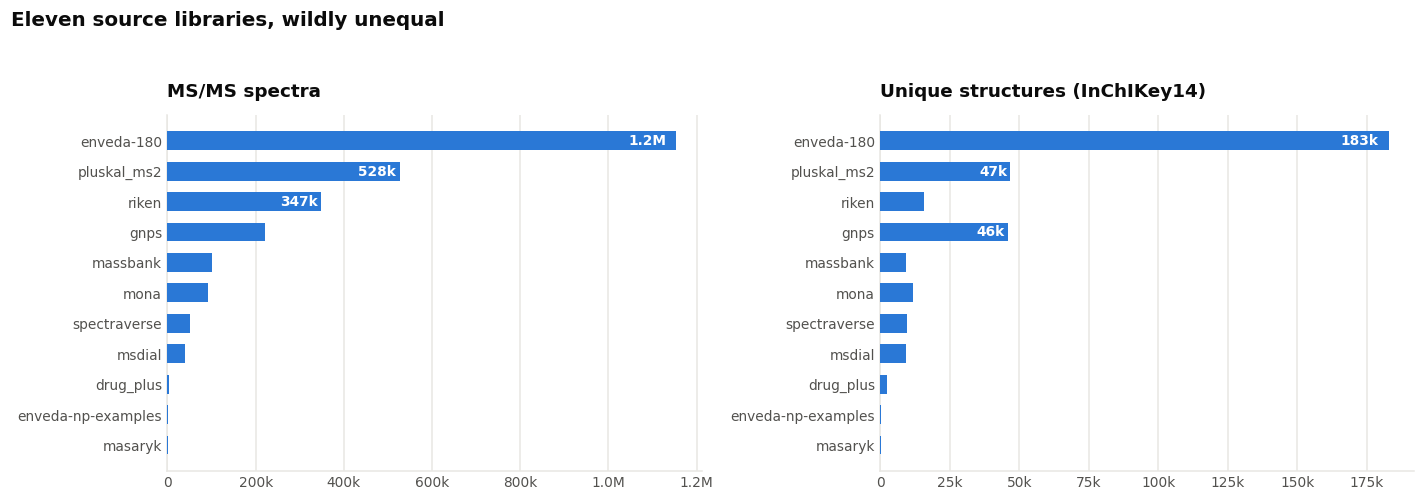

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
o = L.index[::-1]
for ax, col, lab in zip(axes, ["spectra", "structures"],
                        ["MS/MS spectra", "Unique structures (InChIKey14)"]):
    ax.barh(range(len(o)), L.loc[o, col], color=BLUE, height=0.62, zorder=3)
    ax.set_yticks(range(len(o))); ax.set_yticklabels(o)
    ax.xaxis.set_major_formatter(KFMT)
    style(ax, title=lab, grid="x")
    for i, lib in enumerate(o):   # selective direct labels: the top two only
        v = L.loc[lib, col]
        if v >= L[col].max() * 0.25:
            ax.text(v * 0.98, i, thousands(v), va="center", ha="right",
                    color=SURF, fontsize=9, fontweight="bold", zorder=4)
fig.suptitle("Eleven source libraries, wildly unequal", x=0.007, ha="left",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

`enveda-180` alone is **45% of every spectrum in the file** and, at 182,941 structures, **66% of
every structure**. The library that is closest to the test set -- `enveda-np-examples`, gathered on
the same instrument and through the same pipeline -- contributes **250 structures**.

Note also `spec_per_struct`: `riken` measures each structure ~22 times and `drug_plus` exactly
once. A naive per-spectrum train/validation split will scatter a `riken` compound's 22 spectra
across both sides and hand you a wildly optimistic score. **Split on `inchikey14`, never on rows.**

## 4. The libraries barely overlap -- and one of them is an island

The obvious follow-up: do these libraries measure the same molecules? If they did, the
heterogeneity above would be an annoyance. They mostly do not, which makes it a strategy problem.

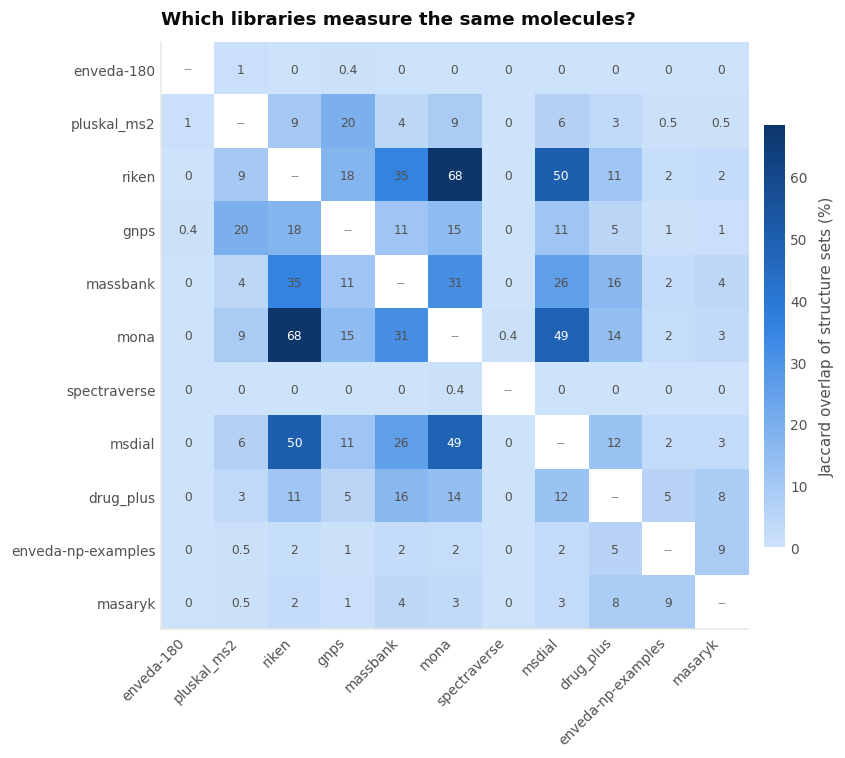

In [6]:
order = list(L.index)
n = len(order)
J = np.zeros((n, n))
for i, a in enumerate(order):
    for j, b in enumerate(order):
        inter = len(sets[a] & sets[b])
        union = len(sets[a]) + len(sets[b]) - inter
        J[i, j] = inter / union * 100 if union else 0.0

fig, ax = plt.subplots(figsize=(8.6, 7.0))
cmap = mpl.colors.LinearSegmentedColormap.from_list("seqblue", SEQ)
M = J.copy(); np.fill_diagonal(M, np.nan)
im = ax.imshow(M, cmap=cmap, vmin=0, vmax=np.nanmax(M))
ax.set_xticks(range(n)); ax.set_xticklabels(order, rotation=45, ha="right")
ax.set_yticks(range(n)); ax.set_yticklabels(order)
for i in range(n):
    for j in range(n):
        if i == j:
            ax.text(j, i, "--", ha="center", va="center", color=INK3, fontsize=8)
        else:
            v = M[i, j]
            ax.text(j, i, f"{v:.0f}" if v >= 0.5 else ("0" if v < 0.05 else f"{v:.1f}"),
                    ha="center", va="center", fontsize=8,
                    color=SURF if v > np.nanmax(M) * 0.55 else INK2)
cb = fig.colorbar(im, ax=ax, shrink=0.72, pad=0.02)
cb.set_label("Jaccard overlap of structure sets (%)", color=INK2)
cb.outline.set_visible(False)
style(ax, title="Which libraries measure the same molecules?", grid="none")
ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout(); plt.show()

In [7]:
np_libs = ["riken", "mona", "msdial", "massbank", "gnps", "enveda-np-examples", "masaryk"]
e180_vs_np = max(J[order.index("enveda-180"), order.index(x)] for x in np_libs)
print(f"enveda-180's largest Jaccard overlap with any natural-product library : {e180_vs_np:.3f}%")
print(f"riken <-> mona                                                         : "
      f"{J[order.index('riken'), order.index('mona')]:.1f}%")
print(f"riken <-> msdial                                                       : "
      f"{J[order.index('riken'), order.index('msdial')]:.1f}%")
print(f"spectraverse's largest overlap with anything                           : "
      f"{max(J[order.index('spectraverse'), k] for k in range(n) if k != order.index('spectraverse')):.1f}%")

enveda-180's largest Jaccard overlap with any natural-product library : 0.354%
riken <-> mona                                                         : 68.5%
riken <-> msdial                                                       : 50.2%
spectraverse's largest overlap with anything                           : 0.4%


Two islands and one continent:

* **`enveda-180` shares essentially nothing with anything** (largest overlap ~0.4%, with GNPS).
  It is 66% of the structures in the file and it is disjoint from the chemistry being tested.
* **`spectraverse` is also isolated** (max overlap 0.4%, with MONA) -- worth a look before you
  trust it; its structures are far heavier than everything else (see the next section).
* The real natural-product continent is **`riken` / `mona` / `msdial` / `massbank`**, which
  overlap each other at 25-68%. Those shared compounds are measured several times on different
  instruments -- which is exactly the raw material for studying instrument transfer.

## 5. Chemical space: the training set is mostly the wrong chemistry

`molecular_formula` gives us real chemistry without needing RDKit. From a formula we can
compute the **monoisotopic exact mass**, the **heteroatom composition**, and the **RDBE**
(ring and double-bond equivalents, `C - H/2 - X/2 + N/2 + 1`) -- the standard unsaturation
measure in mass spectrometry.

In [8]:
MONO = {"C":12.0,"H":1.0078250319,"N":14.0030740052,"O":15.9949146221,"S":31.97207069,
        "P":30.97376151,"F":18.99840320,"Cl":34.96885271,"Br":78.9183376,"I":126.904468,
        "Si":27.9769265327,"Se":79.9165196,"B":11.0093055,"Na":22.98976928,"K":38.96370649,
        "Fe":55.9349375,"D":2.0141017778,"As":74.9215965,"Li":7.0160034,"Sn":119.9021947}
TOK = re.compile(r"([A-Z][a-z]?)(\d*)")

def parse_formula(f):
    if not isinstance(f, str): return None
    d, pos = collections.Counter(), 0
    for m in TOK.finditer(f):
        if m.start() != pos: return None
        pos = m.end()
        d[m.group(1)] += int(m.group(2)) if m.group(2) else 1
    return d if pos == len(f) else None

uni = tr.drop_duplicates("inchikey14")[["inchikey14","molecular_formula","normalized_smiles"]].reset_index(drop=True)
parsed = uni.molecular_formula.map(parse_formula)
for e in ["C","H","N","O","S","P","F","Cl","Br","I"]:
    uni["n"+e] = [d.get(e, 0) if d else np.nan for d in parsed]
uni["heavy"] = [sum(v for k, v in d.items() if k != "H") if d else np.nan for d in parsed]
def mono(d):
    if d is None: return np.nan
    s = 0.0
    for k, v in d.items():
        if k not in MONO: return np.nan
        s += MONO[k] * v
    return s
uni["exact_mass"] = [mono(d) for d in parsed]
X = uni[["nF","nCl","nBr","nI"]].sum(axis=1)
uni["rdbe"] = uni.nC - uni.nH/2 - X/2 + uni.nN/2 + 1
uni["halogen"] = X > 0
print(f"unique structures parsed: {uni.exact_mass.notna().sum():,} / {len(uni):,} "
      f"({uni.exact_mass.isna().sum()} unparseable or exotic-element formulas)")

elems = collections.Counter()
for d in parsed.dropna(): elems.update(d.keys())
print("\nelement prevalence across unique structures")
for e, c in elems.most_common(14):
    print(f"   {e:3} {c:8,}  {c/len(uni)*100:5.1f}%")

unique structures parsed: 275,301 / 275,810 (509 unparseable or exotic-element formulas)

element prevalence across unique structures
   H    275,297   99.8%
   C    275,292   99.8%
   O    268,176   97.2%
   N    255,141   92.5%
   S     70,567   25.6%
   F     51,417   18.6%
   Cl    29,837   10.8%
   Br     8,514    3.1%
   P      5,273    1.9%
   I        367    0.1%
   B         32    0.0%
   Si        28    0.0%
   As        11    0.0%
   Se         7    0.0%


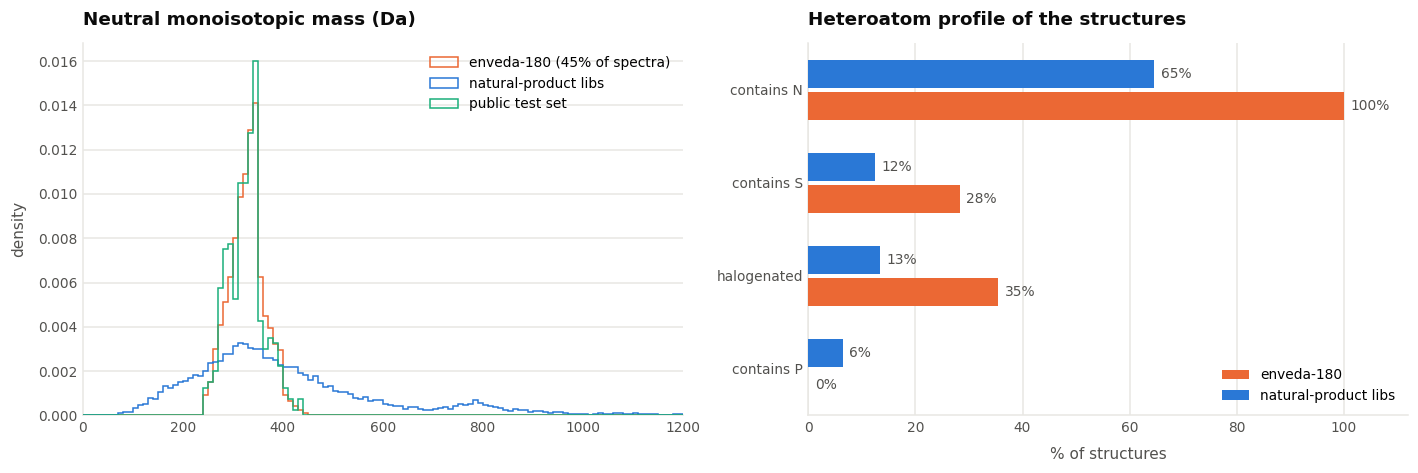

In [10]:
# attach chemistry to every (library, structure) pair
ls  = tr[["ingest_lib","inchikey14"]].drop_duplicates()
chem = ls.merge(uni, on="inchikey14", how="left")

GROUPS = {"enveda-180": ["enveda-180"],
          "natural-product libs": np_libs,
          "test set (implied)": None}

P = 1.00727646
ADDUCT_SHIFT = {"[M+H]+": P, "[M+NH4]+": 18.033823, "[M+Na]+": 22.989218,
                "[M+K]+": 38.963158, "[M-H2O+H]+": P-18.0105646,
                "[M-2H2O+H]+": P-36.0211293, "[M-H]-": -P, "[M+Cl]-": 34.969402,
                "[M+CH2O2-H]-": 46.005479-P, "[M-H2O-H]-": -P-18.0105646,
                "[M+C2H4O2-H]-": 60.021129-P}
te["neutral_mass"] = te.precursor_mz - te.adduct.map(ADDUCT_SHIFT)

m_e180 = chem.loc[chem.ingest_lib == "enveda-180", "exact_mass"].dropna()
m_np   = chem.loc[chem.ingest_lib.isin(np_libs), "exact_mass"].dropna()
m_test = te.drop_duplicates("molecule_id").neutral_mass.dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
bins = np.linspace(0, 1200, 121)
for d, c, lab in [(m_e180, ORANGE, "enveda-180 (45% of spectra)"),
                  (m_np,   BLUE,   "natural-product libs"),
                  (m_test, AQUA,   "public test set")]:
    ax.hist(d, bins=bins, density=True, histtype="step", lw=2, color=c, label=lab, zorder=3)
style(ax, title="Neutral monoisotopic mass (Da)", ylabel="density", legend=True)
ax.set_xlim(0, 1200)

ax = axes[1]
cats = ["contains N", "contains S", "halogenated", "contains P"]
def prof(d):
    return [(d.nN > 0).mean()*100, (d.nS > 0).mean()*100,
            d.halogen.mean()*100, (d.nP > 0).mean()*100]
v1 = prof(chem[chem.ingest_lib == "enveda-180"].dropna(subset=["nN"]))
v2 = prof(chem[chem.ingest_lib.isin(np_libs)].dropna(subset=["nN"]))
y = np.arange(len(cats)); h = 0.34
ax.barh(y + h/2, v1, height=h-0.04, color=ORANGE, label="enveda-180", zorder=3)
ax.barh(y - h/2, v2, height=h-0.04, color=BLUE,   label="natural-product libs", zorder=3)
ax.set_yticks(y); ax.set_yticklabels(cats); ax.invert_yaxis()
for yy, v in zip(y + h/2, v1): ax.text(v+1.2, yy, f"{v:.0f}%", va="center", fontsize=9, color=INK2)
for yy, v in zip(y - h/2, v2): ax.text(v+1.2, yy, f"{v:.0f}%", va="center", fontsize=9, color=INK2)
style(ax, title="Heteroatom profile of the structures", xlabel="% of structures",
      grid="x", legend=True)
ax.set_xlim(0, 112)
fig.tight_layout(); plt.show()

In [11]:
prof = chem.dropna(subset=["exact_mass"]).groupby("ingest_lib").apply(
    lambda d: pd.Series({
        "structures": len(d),
        "mass_p05": d.exact_mass.quantile(.05), "mass_med": d.exact_mass.median(),
        "mass_p95": d.exact_mass.quantile(.95),
        "RDBE_med": d.rdbe.median(),
        "pct_N": (d.nN > 0).mean()*100, "pct_S": (d.nS > 0).mean()*100,
        "pct_halogen": d.halogen.mean()*100,
        "O_per_C": (d.nO / d.nC.replace(0, np.nan)).median()}))
print(prof.round(2).sort_values("structures", ascending=False).to_string())

                    structures  mass_p05  mass_med  mass_p95  RDBE_med  pct_N  pct_S  pct_halogen  O_per_C
ingest_lib                                                                                                
enveda-180            182941.0    268.12    330.12    391.13       9.0  99.96  28.30        35.50     0.14
pluskal_ms2            46667.0    204.04    334.07    530.27      10.0  89.56  30.54        30.37     0.15
gnps                   45536.0    188.06    358.11    726.29       9.0  78.20  16.08        17.17     0.19
riken                  15725.0    161.92    387.17    908.48       8.5  48.54   7.61         9.14     0.25
mona                   11591.0    151.01    359.25    866.52       8.0  49.85   8.37        10.21     0.26
spectraverse            9592.0    262.12    731.55    934.80       6.0  49.25   4.08         4.91     0.16
msdial                  9069.0    150.48    401.98   1154.18       8.5  45.47   6.37         5.24     0.30
massbank                8979.0    136

This is the central tension of the competition, in one table.

`enveda-180` is a **combinatorial drug-discovery screening library**: 99.96% nitrogen-containing,
35% halogenated, O/C ratio 0.14, and a mass distribution squeezed between 268 and 391 Da at the
5th/95th percentiles. It is the only library acquired on the **same timsTOF as the test set**,
so it is the only large source of instrument-matched spectra -- and its chemistry is not the
chemistry you are being asked about.

The natural-product libraries look like natural products: ~47% nitrogen, 5-9% halogen, O/C around
0.25-0.30, and masses spread from 150 to 900+ Da. But they were measured on Orbitraps and QTOFs,
not on a timsTOF.

**You get instrument match or chemistry match, not both.** That gap is the problem to solve, and
`enveda-np-examples` (250 common natural products, test instrument, test pipeline, and deliberately
also present in the other libraries) is the bridge the organisers handed you for measuring it.

## 6. How much evidence per molecule, and how big is the haystack?

Two questions decide how tractable this is: how many spectra does a structure come with, and how
many other structures could plausibly explain the same precursor mass?

In [12]:
spm_tr = tr.groupby("inchikey14").size()
spm_te = te.groupby("molecule_id").size()
iso    = tr.drop_duplicates("inchikey14").groupby("molecular_formula").size()
# weight by structure: what does a randomly chosen structure face?
w_iso  = iso.reindex(tr.drop_duplicates("inchikey14").molecular_formula.values).values

print("spectra per structure (train)"); print(spm_tr.describe(percentiles=[.25,.5,.75,.95,.99]).round(2).to_string())
print(f"\nstructures with a single spectrum : {(spm_tr==1).sum():,} ({(spm_tr==1).mean()*100:.1f}%)")
print(f"most-measured structure           : {spm_tr.max():,} spectra")
print(f"\nspectra per molecule (test)       : median {spm_te.median():.0f}, range {spm_te.min()}-{spm_te.max()}")
print(f"\nisomers sharing a formula, as faced by a random structure:")
print(f"   median {np.median(w_iso):.0f}   mean {np.mean(w_iso):.1f}   "
      f"P(formula is unique in train) = {(w_iso==1).mean()*100:.1f}%")

spectra per structure (train)
count    275810.00
mean          9.21
std          21.07
min           1.00
25%           4.00
50%           6.00
75%           9.00
95%          21.00
99%          79.00
max        1468.00

structures with a single spectrum : 17,033 (6.2%)
most-measured structure           : 1,468 spectra

spectra per molecule (test)       : median 3, range 1-9

isomers sharing a formula, as faced by a random structure:
   median 20   mean 51.8   P(formula is unique in train) = 9.4%


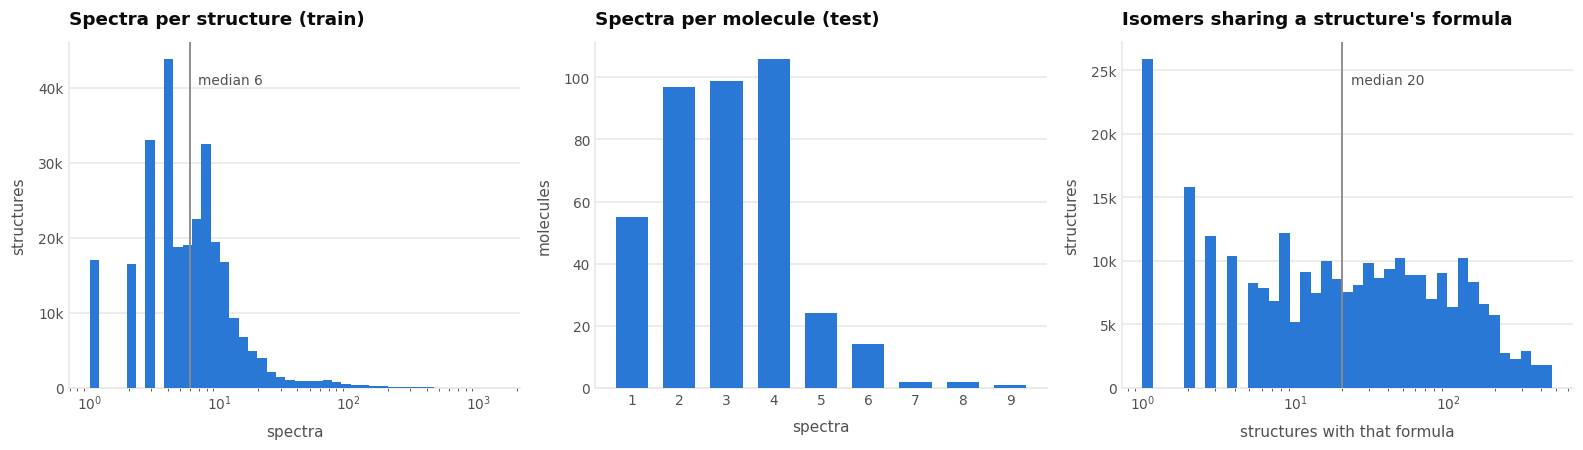

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))

ax = axes[0]
b = np.logspace(0, np.log10(spm_tr.max()), 45)
ax.hist(spm_tr, bins=b, color=BLUE, zorder=3)
ax.set_xscale("log"); ax.yaxis.set_major_formatter(KFMT)
ax.axvline(spm_tr.median(), color=INK3, lw=1.2, ls="-", zorder=4)
ax.text(spm_tr.median()*1.15, ax.get_ylim()[1]*0.88, f"median {spm_tr.median():.0f}",
        color=INK2, fontsize=9)
style(ax, title="Spectra per structure (train)", xlabel="spectra", ylabel="structures")

ax = axes[1]
vc = spm_te.value_counts().sort_index()
ax.bar(vc.index, vc.values, color=BLUE, width=0.68, zorder=3)
style(ax, title="Spectra per molecule (test)", xlabel="spectra", ylabel="molecules")
ax.set_xticks(range(1, int(spm_te.max())+1))

ax = axes[2]
b = np.logspace(0, np.log10(iso.max()), 40)
ax.hist(w_iso, bins=b, color=BLUE, zorder=3)
ax.set_xscale("log"); ax.yaxis.set_major_formatter(KFMT)
ax.axvline(np.median(w_iso), color=INK3, lw=1.2, zorder=4)
ax.text(np.median(w_iso)*1.15, ax.get_ylim()[1]*0.88, f"median {np.median(w_iso):.0f}",
        color=INK2, fontsize=9)
style(ax, title="Isomers sharing a structure's formula", xlabel="structures with that formula",
      ylabel="structures")
fig.tight_layout(); plt.show()

In [14]:
# how many training structures sit inside the mass window of a test precursor?
masses = np.sort(uni.exact_mass.dropna().values)
def n_within(m, ppm):
    d = m * ppm * 1e-6
    return np.searchsorted(masses, m + d) - np.searchsorted(masses, m - d)

rows = []
np_mass = chem.loc[chem.ingest_lib == "enveda-np-examples", "exact_mass"].dropna()
for ppm in [3, 5, 10, 20]:
    a = np.array([n_within(m, ppm) for m in te.neutral_mass.dropna()])
    b = np.array([n_within(m, ppm) for m in np_mass])
    rows.append({"window": f"+/-{ppm} ppm",
                 "test: median": int(np.median(a)), "test: mean": round(a.mean(), 1),
                 "test: p95": int(np.percentile(a, 95)),
                 "NP-like: median": int(np.median(b)), "NP-like: mean": round(b.mean(), 1)})
cand = pd.DataFrame(rows)
print("Training structures whose exact mass is compatible with the measured precursor\n")
print(cand.to_string(index=False))

Training structures whose exact mass is compatible with the measured precursor

   window  test: median  test: mean  test: p95  NP-like: median  NP-like: mean
 +/-3 ppm            38        73.2        291                7           15.7
 +/-5 ppm            58        93.9        338               10           20.0
+/-10 ppm            82       118.3        360               13           26.8
+/-20 ppm           126       163.5        403               18           43.4


Read those two numbers together and you have the shape of the search problem.

A perfect molecular-formula prediction -- the thing SIRIUS and MIST-CF are for, and a standard
first stage -- leaves you with a **median of 20 candidate structures drawn from the training set
alone**. Only **9.4%** of structures have a formula that is unique even within this file. Against
PubChem (which is where Class-2 molecules live) the candidate list for a typical formula runs into
the thousands.

With 25 submission slots and MRR@25 scoring, the formula is a filter, not an answer. The ranking
inside the filtered list is where the score is.

One asymmetry in your favour: natural-product-like masses sit in a **much sparser** part of mass
space (median 10 compatible structures at 5 ppm, against 58 for the public test file's drug-like
masses). Natural products carry more oxygen and fewer nitrogens, which pushes their mass defect
away from the crowded drug-like region.

## 7. Reading the peak arrays (one pass over 3 GB)

Now we open the two array columns. Rather than load 2.5M peak lists, we do **one streaming pass**
over the parquet row groups and pull out exactly the rows we need:

* a **stratified sample** (up to 8,000 spectra per library) for peak-level statistics, and
* the **reference spectra** for the retrieval baseline in section 13.

Extracting through pyarrow's list offsets rather than `to_pandas()` keeps this cheap -- no Python
object arrays are ever built.

In [15]:
rng = np.random.default_rng(7)
SAMPLE_PER_LIB = 8000

samp_idx = (tr.groupby("ingest_lib", group_keys=False)
              .apply(lambda d: d.sample(min(len(d), SAMPLE_PER_LIB), random_state=7)))
sample_g = set(samp_idx.gidx.tolist())
print(f"stratified sample: {len(sample_g):,} spectra")

# --- reference rows for the section-13 baseline: everything within 10 ppm of an
#     enveda-np-examples precursor, same adduct, excluding that library itself ---
q   = tr[tr.ingest_lib == "enveda-np-examples"]
ref = tr[tr.ingest_lib != "enveda-np-examples"]
cand_map, need = {}, set()
for add, qa in q.groupby("adduct"):
    ra = ref[ref.adduct == add].sort_values("precursor_mz")
    mz, gi = ra.precursor_mz.values, ra.gidx.values
    for gq, m in zip(qa.gidx.values, qa.precursor_mz.values):
        d = m * 10e-6
        c = gi[np.searchsorted(mz, m - d):np.searchsorted(mz, m + d)]
        cand_map[gq] = c
        need.update(c.tolist())
need.update(q.gidx.tolist())
print(f"baseline reference rows   : {len(need):,} spectra")

WANT = sample_g | need
print(f"total rows to extract     : {len(WANT):,}  ({len(WANT)/len(tr)*100:.1f}% of train)")

stratified sample: 68,381 spectra
baseline reference rows   : 85,463 spectra
total rows to extract     : 148,911  (5.9% of train)


In [16]:
t0 = time.time()
pf = pq.ParquetFile(TRAIN_P)
offs = np.cumsum([0] + [pf.metadata.row_group(i).num_rows for i in range(pf.metadata.num_row_groups)])
PEAKS = {}          # gidx -> (mz array, intensity array)
for rg in range(pf.metadata.num_row_groups):
    lo, hi = offs[rg], offs[rg+1]
    loc = np.array(sorted(i - lo for i in WANT if lo <= i < hi), dtype=np.int64)
    if len(loc) == 0:
        continue
    tbl = pf.read_row_group(rg, columns=["ms2_mzs", "ms2_normalized_intensities"])
    mzc = tbl.column("ms2_mzs").combine_chunks()
    inc = tbl.column("ms2_normalized_intensities").combine_chunks()
    mo, mv = mzc.offsets.to_numpy(), mzc.values.to_numpy()
    io, iv = inc.offsets.to_numpy(), inc.values.to_numpy()
    for k in loc:
        # .copy() matters: a bare slice is a VIEW that would pin the whole
        # 250 MB row-group buffer in memory for as long as we keep it.
        PEAKS[int(k + lo)] = (mv[mo[k]:mo[k+1]].copy(), iv[io[k]:io[k+1]].copy())
    del tbl, mzc, inc, mv, iv
print(f"extracted {len(PEAKS):,} peak lists in {time.time()-t0:.1f}s")

extracted 148,911 peak lists in 51.0s


## 8. Anatomy of a spectrum

Before the aggregate statistics, look at one. The panels below are the **same test spectrum**
twice: once with every peak the instrument recorded on a log intensity axis, and once after a 1%
relative-intensity floor. Nothing is removed between them except noise.

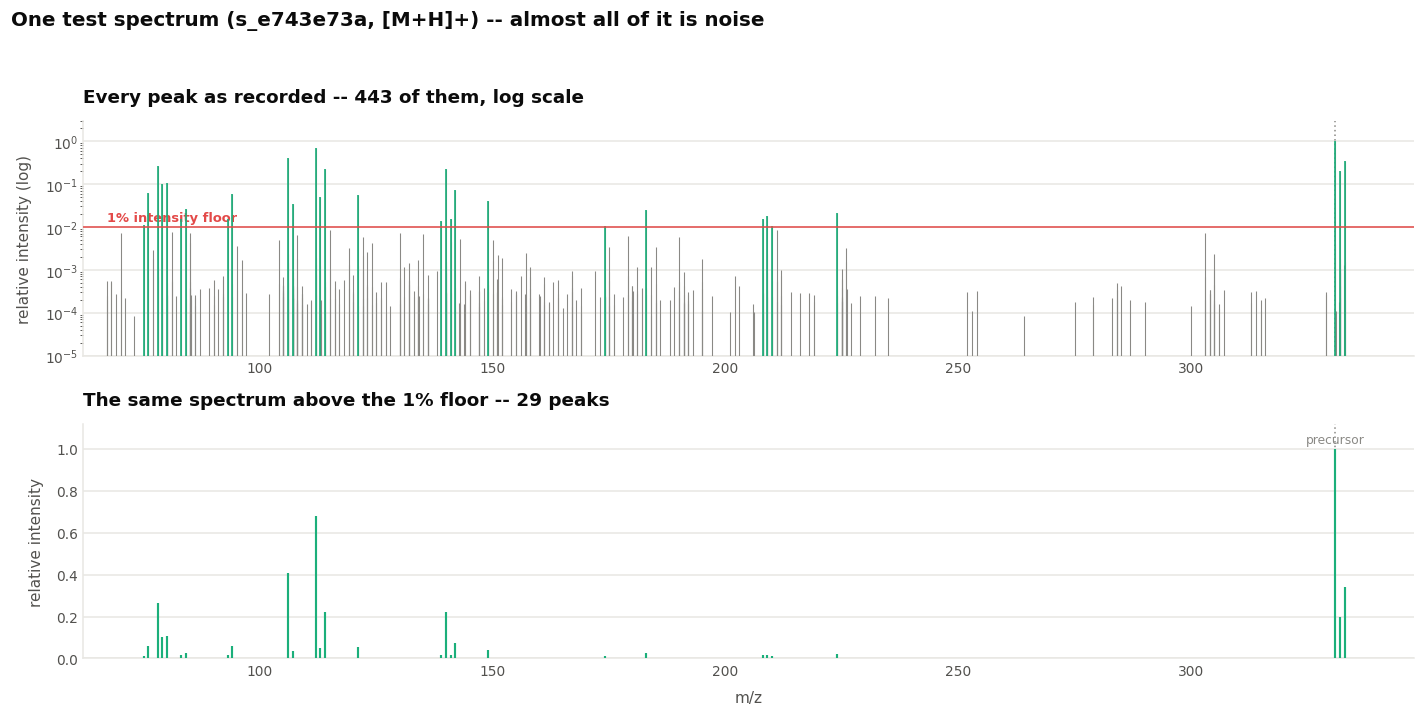

peaks recorded 443   |   above 1% floor 29   |   they carry 93.0% of the total ion intensity


In [17]:
# a peak-rich test spectrum, so the noise carpet is actually visible
ts = te.iloc[(te.num_peaks - te.num_peaks.quantile(0.75)).abs().argsort().iloc[0]]
mz = np.asarray(ts.ms2_mzs, float)
it = np.asarray(ts.ms2_normalized_intensities, float)
keep = it >= 0.01

fig, axes = plt.subplots(2, 1, figsize=(13, 6.6))

ax = axes[0]
ax.vlines(mz, 1e-5, it, color=INK3, lw=0.7, zorder=3)
ax.vlines(mz[keep], 1e-5, it[keep], color=AQUA, lw=1.1, zorder=4)
ax.set_yscale("log"); ax.set_ylim(1e-5, 3)
ax.axhline(0.01, color=RED, lw=1.0, zorder=5)
ax.text(mz.min(), 0.014, "1% intensity floor", color=RED, fontsize=8.5, fontweight="bold")
style(ax, title=f"Every peak as recorded -- {len(mz)} of them, log scale",
      ylabel="relative intensity (log)")

ax = axes[1]
ax.vlines(mz[keep], 0, it[keep], color=AQUA, lw=1.4, zorder=3)
ax.set_ylim(0, 1.12)
style(ax, title=f"The same spectrum above the 1% floor -- {int(keep.sum())} peaks",
      xlabel="m/z", ylabel="relative intensity")
for a in axes:
    a.axvline(ts.precursor_mz, color=INK3, lw=1.0, ls=(0, (1, 2)), zorder=2)
    a.set_xlim(mz.min() - 5, max(mz.max(), ts.precursor_mz) + 15)
axes[1].text(ts.precursor_mz, 1.03, "precursor", color=INK3, fontsize=8, ha="center")

fig.suptitle(f"One test spectrum ({ts.spectrum_id}, {ts.adduct}) -- almost all of it is noise",
             x=0.007, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout(rect=[0, 0, 1, 0.945]); plt.show()
print(f"peaks recorded {len(mz):,}   |   above 1% floor {int(keep.sum())}   "
      f"|   they carry {it[keep].sum()/it.sum()*100:.1f}% of the total ion intensity")

In [18]:
def peak_table(mz, it, pmz):
    return dict(n=len(mz),
                mz_min=mz.min() if len(mz) else np.nan,
                mz_max=mz.max() if len(mz) else np.nan,
                frac_above_prec=float((mz > pmz + 2).mean()) if len(mz) else np.nan,
                frac_below_1pct=float((it < 0.01).mean()) if len(mz) else np.nan,
                n_ge_1pct=int((it >= 0.01).sum()),
                precursor_present=float(np.any(np.abs(mz - pmz) < 0.01)) if len(mz) else 0.0)

ps = pd.DataFrame([peak_table(*PEAKS[g], p)
                   for g, p in zip(samp_idx.gidx.values, samp_idx.precursor_mz.values)])
ps["ingest_lib"] = samp_idx.ingest_lib.values
pt = pd.DataFrame([peak_table(np.asarray(a, float), np.asarray(b, float), p)
                   for a, b, p in zip(te.ms2_mzs, te.ms2_normalized_intensities, te.precursor_mz)])

summary = ps.groupby("ingest_lib").agg(
    spectra=("n", "size"), raw_peaks_med=("n", "median"),
    peaks_ge_1pct_med=("n_ge_1pct", "median"),
    pct_peaks_below_1pct=("frac_below_1pct", lambda s: round(s.mean()*100, 1)),
    pct_with_precursor=("precursor_present", lambda s: round(s.mean()*100, 1)),
    pct_peaks_above_prec=("frac_above_prec", lambda s: round(s.mean()*100, 2)))
summary.loc["** TEST SET **"] = [len(pt), pt.n.median(), pt.n_ge_1pct.median(),
                                 round(pt.frac_below_1pct.mean()*100, 1),
                                 round(pt.precursor_present.mean()*100, 1),
                                 round(pt.frac_above_prec.mean()*100, 2)]
print(summary.to_string())

                    spectra  raw_peaks_med  peaks_ge_1pct_med  pct_peaks_below_1pct  pct_with_precursor  pct_peaks_above_prec
ingest_lib                                                                                                                   
drug_plus            2545.0          108.0               27.0                  52.4                60.5                  0.06
enveda-180           8000.0          141.0               14.0                  75.2                47.0                  0.25
enveda-np-examples   1184.0          141.5               28.0                  61.2                55.6                  0.00
gnps                 8000.0           45.0               18.0                  48.1                57.2                  2.83
masaryk               652.0            9.0                6.0                  30.6                17.9                  0.00
massbank             8000.0           11.0                9.0                  18.6                42.0               

### The noise-floor illusion

The `raw_peaks_med` column says test spectra have **230 peaks** against a training median of
**~27**, which looks like a serious distribution shift. It is not. Look at the next two columns:
**82% of the peaks in a test spectrum sit below 1% relative intensity**, and once you apply a
1% floor the median test spectrum has **18 real peaks** against 14 for the training pool.

Raw peak count in this file is a record of **how aggressively each upstream library thresholded
its data**, not of how much chemical information a spectrum carries. `riken` ships 8 peaks
because someone already cut it at ~1%; the test set ships 230 because it is deliberately
uncurated. Comparing them before you normalise the floor will mislead you about everything else.

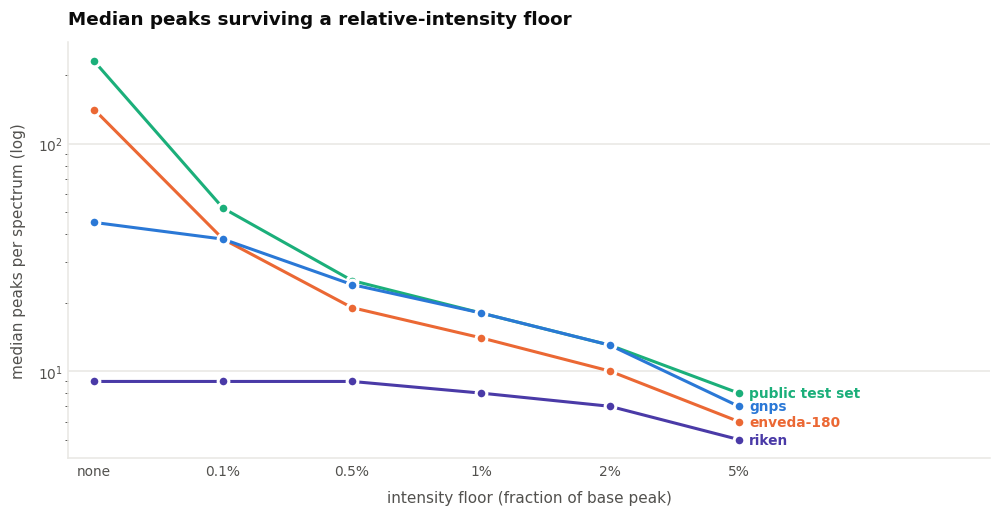

In [19]:
THR = [0.0, 0.001, 0.005, 0.01, 0.02, 0.05]
def surviving(mzs_its):
    return [float(np.median([(it >= t).sum() for _, it in mzs_its])) for t in THR]

series = [("public test set", [(np.asarray(a, float), np.asarray(b, float))
                              for a, b in zip(te.ms2_mzs, te.ms2_normalized_intensities)], AQUA),
          ("enveda-180",  [PEAKS[g] for g in samp_idx[samp_idx.ingest_lib=="enveda-180"].gidx], ORANGE),
          ("gnps",        [PEAKS[g] for g in samp_idx[samp_idx.ingest_lib=="gnps"].gidx], BLUE),
          ("riken",       [PEAKS[g] for g in samp_idx[samp_idx.ingest_lib=="riken"].gidx], VIOLET)]

fig, ax = plt.subplots(figsize=(9.2, 4.8))
x = np.arange(len(THR))
for lab, data, c in series:
    y = surviving(data)
    ax.plot(x, y, color=c, lw=2, marker="o", ms=7, label=lab, zorder=3,
            markeredgecolor=SURF, markeredgewidth=2)
    ax.text(x[-1] + 0.08, y[-1], lab, color=c, fontsize=9, va="center", fontweight="bold")
ax.set_yscale("log")
ax.set_xticks(x); ax.set_xticklabels(["none", "0.1%", "0.5%", "1%", "2%", "5%"])
ax.set_xlim(-0.2, len(THR) + 0.95)
style(ax, title="Median peaks surviving a relative-intensity floor",
      xlabel="intensity floor (fraction of base peak)", ylabel="median peaks per spectrum (log)")
fig.tight_layout(); plt.show()

Four libraries that look nothing alike at the left edge are **within a factor of three of each
other by the 1% floor**. That single preprocessing choice removes most of the apparent
heterogeneity in this dataset -- it is the highest-leverage line of code in your pipeline.

Two more things the table above reports:

* **The precursor peak often is not there at all** -- it survives in 18% to 64% of spectra
  depending on the library, and 56% of the test set. You cannot rely on seeing the intact ion;
  `precursor_mz` is metadata, not a peak.
* **`riken` has 11% of its peaks above the precursor** where the test set has 0.3% (all within
  the documented +2 Da isotope allowance). Those are co-isolated contaminants that the test set
  has had removed for you -- so remove them from train too, or your model will learn to expect
  peaks that can never appear at inference.

## 9. Adducts and ionization

The adduct determines how the measured `precursor_mz` maps back to a neutral mass, so getting it
wrong shifts every downstream mass calculation. Train carries **121 distinct adducts**; the test
set is restricted to a documented **ten** (of which seven actually appear in the public file).

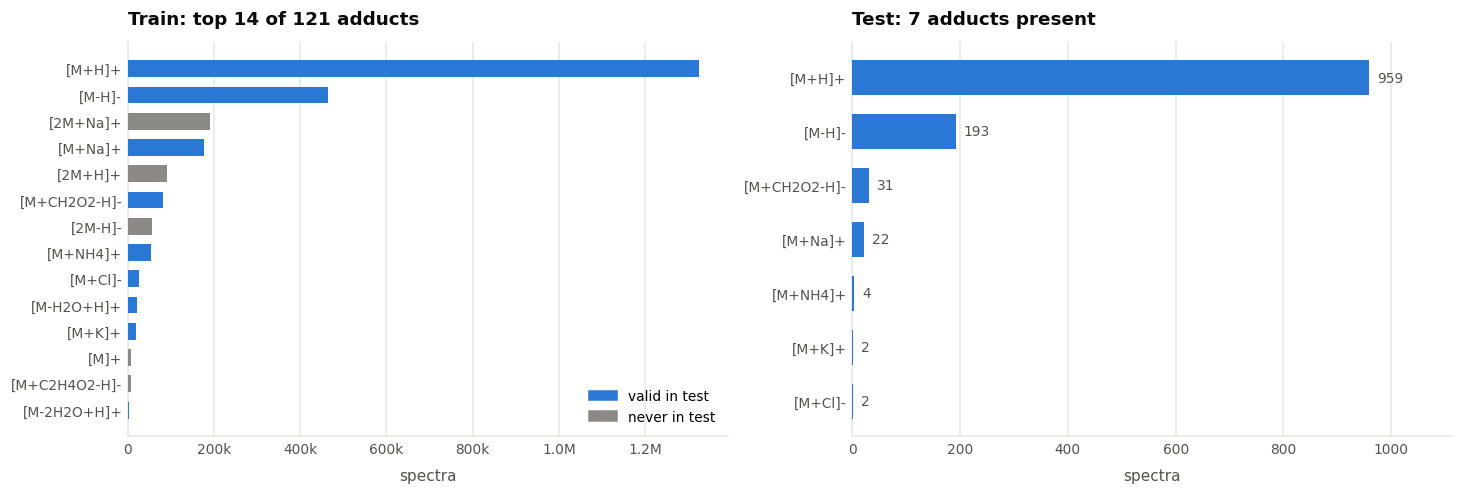

train spectra whose adduct can ever occur in test : 2,176,877 (85.7%)
train spectra on multimer/exotic adducts          : 362,731 (14.3%)

ionization mode   train: {'positive': np.int64(1899640), 'negative': np.int64(639968)}
                  test : {'positive': np.int64(987), 'negative': np.int64(226)}

instrument_type   train: 82 distinct free-text strings (33,053 null)
                  test : {'timsTOF': np.int64(1213)}


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.6))
TEST_ADDUCTS = ["[M+H]+","[M+NH4]+","[M-H2O+H]+","[M-2H2O+H]+","[M+Na]+","[M+K]+",
                "[M-H]-","[M-H2O-H]-","[M+CH2O2-H]-","[M+Cl]-"]

ax = axes[0]
v = tr.adduct.value_counts().head(14)[::-1]
cols = [BLUE if a in TEST_ADDUCTS else INK3 for a in v.index]
ax.barh(range(len(v)), v.values, color=cols, height=0.64, zorder=3)
ax.set_yticks(range(len(v))); ax.set_yticklabels(v.index)
ax.xaxis.set_major_formatter(KFMT)
style(ax, title=f"Train: top 14 of {tr.adduct.nunique()} adducts", xlabel="spectra", grid="x")
h = [mpl.patches.Patch(color=BLUE, label="valid in test"),
     mpl.patches.Patch(color=INK3, label="never in test")]
ax.legend(handles=h, loc="lower right")

ax = axes[1]
v = te.adduct.value_counts()[::-1]
ax.barh(range(len(v)), v.values, color=BLUE, height=0.64, zorder=3)
ax.set_yticks(range(len(v))); ax.set_yticklabels(v.index)
for i, val in enumerate(v.values):
    ax.text(val + v.max()*0.015, i, f"{val:,}", va="center", fontsize=9, color=INK2)
style(ax, title="Test: 7 adducts present", xlabel="spectra", grid="x")
ax.set_xlim(0, v.max()*1.16)
fig.tight_layout(); plt.show()

usable = tr.adduct.isin(TEST_ADDUCTS)
print(f"train spectra whose adduct can ever occur in test : {usable.sum():,} "
      f"({usable.mean()*100:.1f}%)")
print(f"train spectra on multimer/exotic adducts          : {(~usable).sum():,} "
      f"({(~usable).mean()*100:.1f}%)")
print(f"\nionization mode   train: {dict(tr.ionization_mode.value_counts())}")
print(f"                  test : {dict(te.ionization_mode.value_counts())}")
print(f"\ninstrument_type   train: {tr.instrument_type.nunique()} distinct free-text strings "
      f"({tr.instrument_type.isna().sum():,} null)")
print(f"                  test : {dict(te.instrument_type.value_counts())}")

**14.3% of the training set sits on adducts that can never appear in the test set** -- mostly
`[2M+Na]+`, `[2M+H]+` and `[2M-H]-` dimers, which fragment differently from monomers. That is
a defensible ~363k rows to drop, or at minimum to flag as a feature.

Note too that positive mode is 75% of train and 81% of test, but negative mode is not rare enough
to ignore -- and a molecule in the test set is frequently measured in **both** modes. The two
spectra of one molecule in opposite modes are genuinely complementary evidence, which is the whole
point of the "predictions are per molecule, not per spectrum" rule.

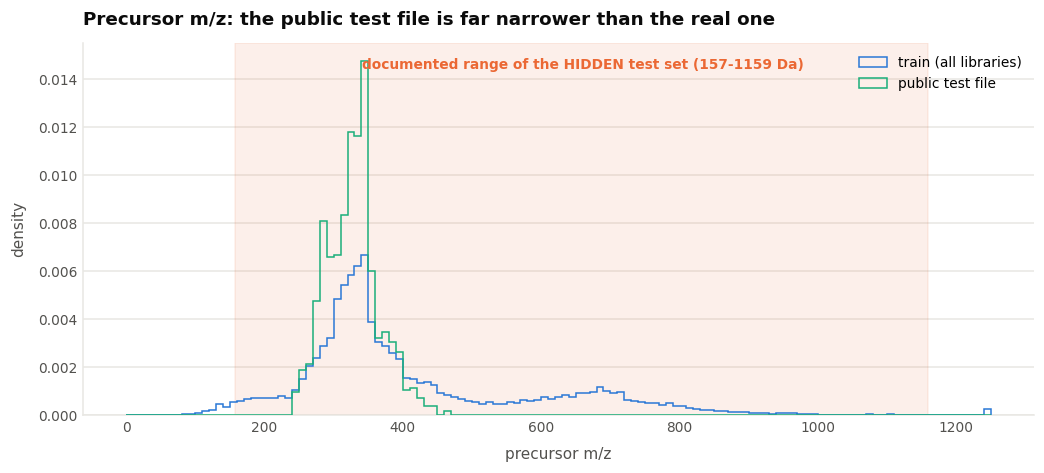

public test precursor m/z : 245 - 460 Da (median 329)
hidden test, per the data page: 157 - 1159 Da (median 348)


In [21]:
fig, ax = plt.subplots(figsize=(9.6, 4.4))
bins = np.linspace(0, 1250, 126)
ax.hist(tr.precursor_mz.clip(0, 1250), bins=bins, density=True, histtype="step",
        lw=2, color=BLUE, label="train (all libraries)", zorder=3)
ax.hist(te.precursor_mz, bins=bins, density=True, histtype="step",
        lw=2, color=AQUA, label="public test file", zorder=3)
ax.axvspan(157, 1159, color=ORANGE, alpha=0.10, zorder=1)
ax.text(660, ax.get_ylim()[1]*0.93, "documented range of the HIDDEN test set (157-1159 Da)",
        color=ORANGE, fontsize=9, ha="center", fontweight="bold")
style(ax, title="Precursor m/z: the public test file is far narrower than the real one",
      xlabel="precursor m/z", ylabel="density", legend=True)
fig.tight_layout(); plt.show()
print(f"public test precursor m/z : {te.precursor_mz.min():.0f} - {te.precursor_mz.max():.0f} Da "
      f"(median {te.precursor_mz.median():.0f})")
print( "hidden test, per the data page: 157 - 1159 Da (median 348)")

## 10. Collision energy: the one metadata column that is physics

Collision energy controls how hard the molecule is hit, and therefore how completely it breaks.
It is also the messiest column in the file: instruments report absolute eV, Thermo's normalised
NCE percentage, raw voltages, or nothing.

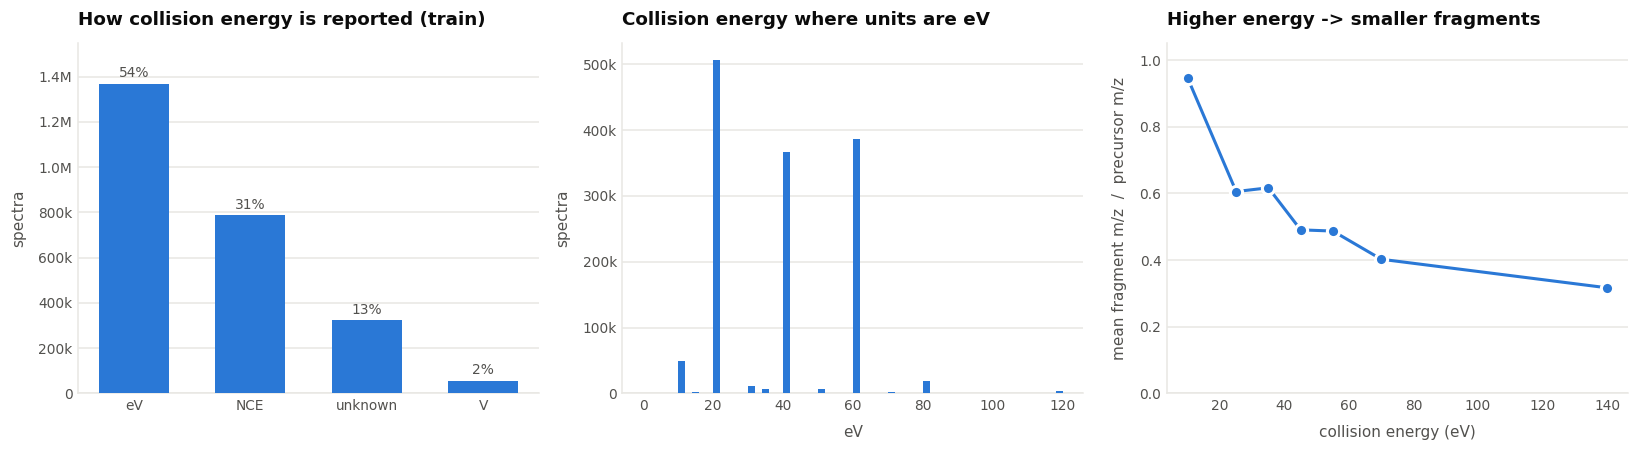

spectra merged from several energies (comma/space in collision_energy_orig): 632,075
test spectra that are multi-energy merges: 298 of 1213


In [22]:
def first_num(s):
    if not isinstance(s, str): return np.nan
    f = re.findall(r"-?\d+\.?\d*", s)
    return abs(float(f[0])) if f else np.nan

ev = tr[tr.collision_energy_orig_units == "eV"].copy()
ev["ce"] = ev.collision_energy_orig.map(first_num)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
u = tr.collision_energy_orig_units.value_counts()
ax.bar(range(len(u)), u.values, color=BLUE, width=0.6, zorder=3)
ax.set_xticks(range(len(u))); ax.set_xticklabels(u.index)
ax.yaxis.set_major_formatter(KFMT)
for i, v in enumerate(u.values):
    ax.text(i, v + u.max()*0.02, f"{v/len(tr)*100:.0f}%", ha="center", fontsize=9, color=INK2)
style(ax, title="How collision energy is reported (train)", ylabel="spectra")
ax.set_ylim(0, u.max()*1.13)

ax = axes[1]
ax.hist(ev.ce.clip(0, 120), bins=np.arange(0, 122, 2), color=BLUE, zorder=3)
ax.yaxis.set_major_formatter(KFMT)
style(ax, title="Collision energy where units are eV", xlabel="eV", ylabel="spectra")

ax = axes[2]
s = samp_idx[samp_idx.collision_energy_orig_units == "eV"].copy()
s["ce"] = s.collision_energy_orig.map(first_num)
rel = []
for g, p in zip(s.gidx.values, s.precursor_mz.values):
    mz, it = PEAKS[g]
    k = it >= 0.01
    rel.append(np.average(mz[k], weights=it[k]) / p if k.sum() else np.nan)
s["rel_frag_mass"] = rel
EDGES = [0, 20, 30, 40, 50, 60, 80, 200]
b = pd.cut(s.ce, EDGES, right=False)
gg = s.groupby(b, observed=True).rel_frag_mass.median()
xs = [(EDGES[i] + EDGES[i+1]) / 2 for i in range(len(EDGES)-1)][:len(gg)]
ax.plot(xs, gg.values, color=BLUE, lw=2, marker="o", ms=8,
        markeredgecolor=SURF, markeredgewidth=2, zorder=3)
style(ax, title="Higher energy -> smaller fragments",
      xlabel="collision energy (eV)",
      ylabel="mean fragment m/z  /  precursor m/z")
ax.set_ylim(0, 1.05)
fig.tight_layout(); plt.show()

print(f"spectra merged from several energies (comma/space in collision_energy_orig): "
      f"{tr.collision_energy_orig.fillna('').str.contains(r'[,\s]').sum():,}")
print(f"test spectra that are multi-energy merges: {(te.collision_energy_ev.map(len) > 1).sum()} "
      f"of {len(te)}")

The right-hand panel is the cleanest signal in the whole dataset: the intensity-weighted mean
fragment mass falls monotonically from **0.95x the precursor below 20 eV to 0.32x above 80 eV**.
Collision energy is not a nuisance covariate -- it is the single strongest predictor of what a
spectrum will look like, and any model that ignores it is being asked to average over a factor-of-three
difference in fragmentation.

Two practical notes. **Use `collision_energy_ev`**, not `collision_energy_orig` -- it is the
column converted to the test set's convention; the NCE conversion is approximate but consistent.
And **13% of training rows have no usable energy at all** (`unknown` units), so your architecture
needs a missing-energy path.

The test set acquires each molecule at 20, 40 and 60 eV plus a merged spectrum of all three, in
both polarities. That structure -- an energy ladder per molecule -- is deliberate, and a model
that consumes the ladder jointly has strictly more information than one scoring each spectrum
alone.

## 11. What the peaks actually say: neutral losses and diagnostic fragments

Two complementary views of fragmentation. A **neutral loss** (precursor minus fragment) names the
group that fell off; a **fragment m/z** names the piece that survived and kept the charge.

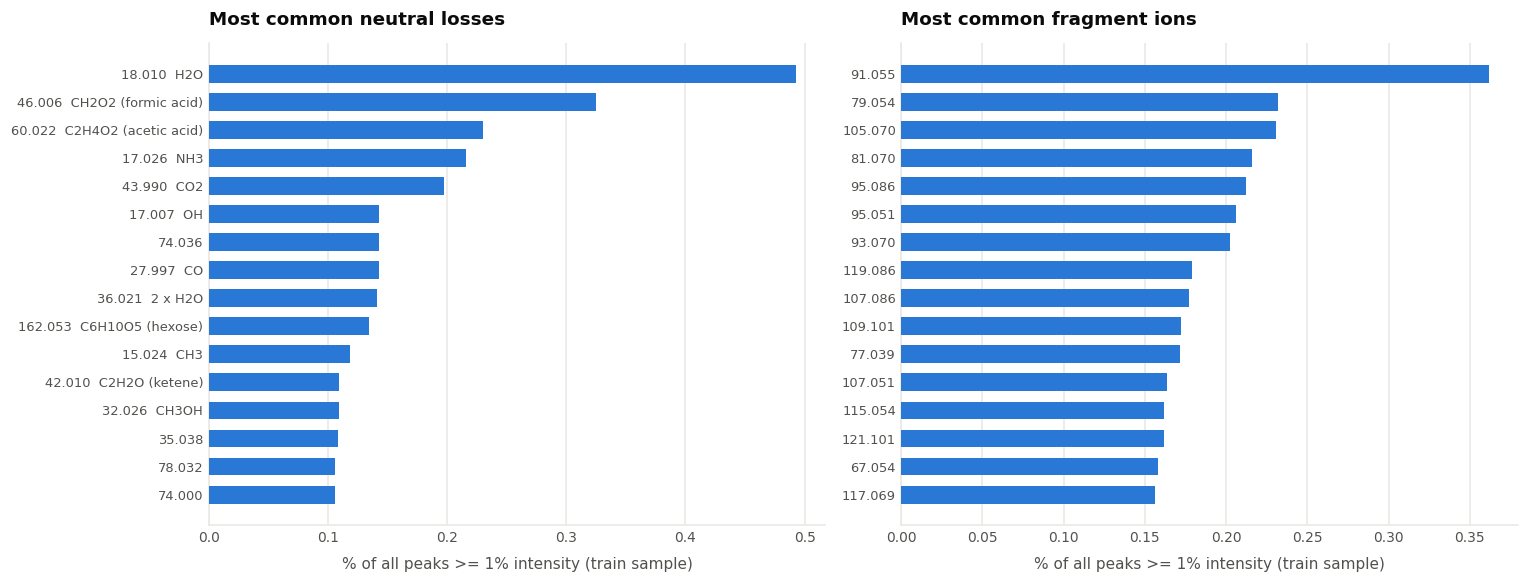

In [23]:
NAMED = {18.0106:"H2O", 17.0265:"NH3", 27.9949:"CO", 28.0313:"C2H4", 30.0106:"CH2O",
         32.0262:"CH3OH", 34.0055:"H2S", 35.9767:"HCl", 42.0106:"C2H2O (ketene)",
         43.9898:"CO2", 44.0262:"C2H6O", 46.0055:"CH2O2 (formic acid)", 46.0419:"C2H6O",
         59.0371:"C2H5NO", 60.0211:"C2H4O2 (acetic acid)", 62.0004:"CH2O3",
         79.9568:"SO3", 90.0317:"C3H6O3", 97.9769:"H3PO4", 120.0423:"C4H8O4",
         132.0423:"C5H8O4 (pentose)", 146.0579:"C6H10O4 (deoxyhexose)",
         162.0528:"C6H10O5 (hexose)", 176.0321:"C6H8O6 (glucuronide)",
         36.0211:"2 x H2O", 54.0317:"3 x H2O", 15.0235:"CH3", 17.0027:"OH"}
def name_loss(v, tol=0.012):
    for m, nm in NAMED.items():
        if abs(v - m) < tol: return nm
    return ""

MZ_GRID = 0.002                   # fine histogram, then centroid it
def count_losses(pairs, prec, thr=0.01, maxloss=250):
    c = collections.Counter()
    for (mz, it), p in zip(pairs, prec):
        Lv = p - mz[it >= thr]
        Lv = Lv[(Lv > 0.5) & (Lv < maxloss)]
        c.update(np.round(Lv / MZ_GRID).astype(int).tolist())
    return c
def count_frags(pairs, thr=0.01):
    c = collections.Counter()
    for mz, it in pairs:
        c.update(np.round(mz[it >= thr] / MZ_GRID).astype(int).tolist())
    return c

def centroid(counter, halfwidth=0.012, topn=16):
    '''Peak-pick the histogram instead of trusting a fixed bin grid: a real loss
       straddling a bin edge would otherwise be split into two half-height entries.'''
    items = sorted(counter.items())
    vals = np.array([k * MZ_GRID for k, _ in items])
    cnts = np.array([v for _, v in items], dtype=float)
    used = np.zeros(len(vals), bool)
    out = []
    for i in np.argsort(-cnts):
        if used[i]:
            continue
        sel = (np.abs(vals - vals[i]) <= halfwidth) & (~used)
        out.append((float(np.average(vals[sel], weights=cnts[sel])), float(cnts[sel].sum())))
        used |= sel
        if len(out) >= topn * 4:
            break
    out.sort(key=lambda t: -t[1])
    return out[:topn]

train_pairs = [PEAKS[g] for g in samp_idx.gidx.values]
loss_c = count_losses(train_pairs, samp_idx.precursor_mz.values)
frag_c = count_frags(train_pairs)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, ctr, ttl, is_loss in [(axes[0], loss_c, "Most common neutral losses", True),
                              (axes[1], frag_c, "Most common fragment ions", False)]:
    tot = sum(ctr.values())
    top = centroid(ctr)[::-1]
    vals = [v / tot * 100 for _, v in top]
    labs = []
    for m, _ in top:
        nm = name_loss(m) if is_loss else ""
        labs.append(f"{m:.3f}  {nm}" if nm else f"{m:.3f}")
    ax.barh(range(len(top)), vals, color=BLUE, height=0.64, zorder=3)
    ax.set_yticks(range(len(top))); ax.set_yticklabels(labs, fontsize=8.5)
    style(ax, title=ttl, xlabel="% of all peaks >= 1% intensity (train sample)", grid="x")
fig.tight_layout(); plt.show()

Both panels are chemistry you can verify by eye, which is a good sign the file is sound.

The masses come out right to three decimals, which is a good sign the file is sound: the bars are
centroided from a 2 mDa histogram rather than read off a fixed bin grid, so a loss landing on a bin
edge is not split into two half-height entries.

**Losses** are dominated by water (18.010), then formic acid (46.006), acetic acid (60.022),
ammonia (17.026) and CO2 (43.990) -- the standard repertoire. The 162.053 entry is a **hexose**:
that is glycoside cleavage, and it is a direct readout of how many sugar-conjugated natural
products are in this file.

**Fragments** are the classic stabilised cations: 91.055 is tropylium (C7H7+, the benzyl signature),
77.039 is phenyl, 105.070 is C8H9+. The 81.070 / 95.086 / 109.101 ladder is the terpenoid
hydrocarbon series, spaced by CH2.

A neutral loss is precursor-relative and a fragment is absolute, so the two carry different
information -- which is exactly why modified cosine (matching peaks on both the direct and the
precursor-shifted axis) beats plain cosine for analogue retrieval.

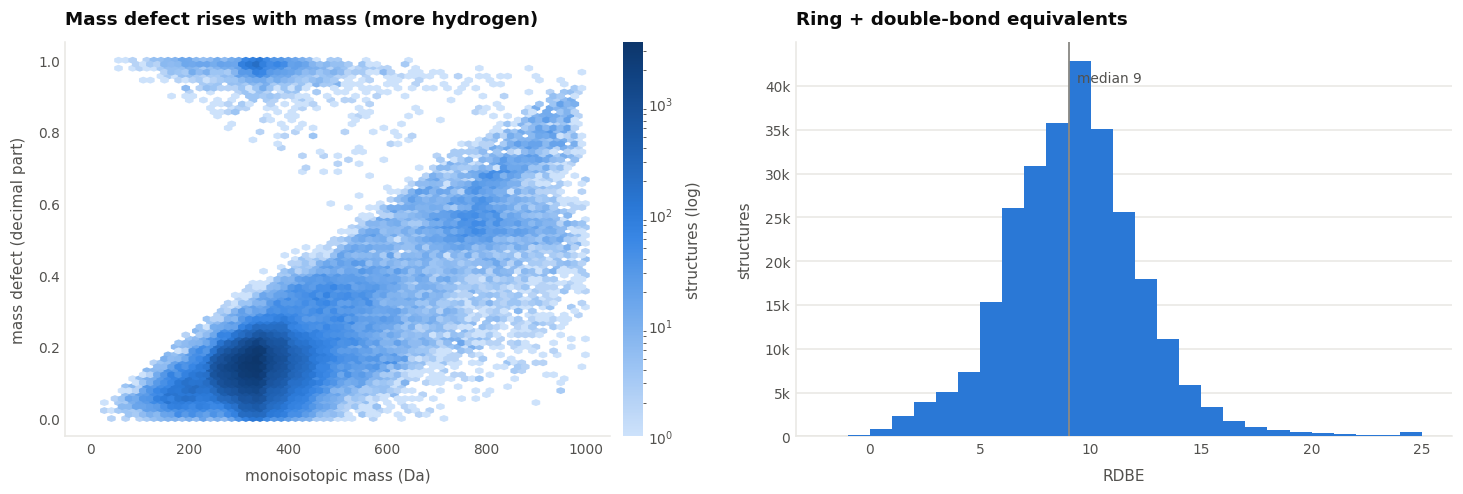

correlation(mass, mass defect) = 0.578
structures with RDBE < 0 (impossible for a neutral molecule): 192


In [24]:
uu = uni.dropna(subset=["exact_mass"])
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.6))

ax = axes[0]
hb = ax.hexbin(uu.exact_mass, uu.exact_mass - np.floor(uu.exact_mass),
               gridsize=(70, 45), bins="log", extent=(0, 1000, 0, 1),
               cmap=mpl.colors.LinearSegmentedColormap.from_list("s", SEQ), mincnt=1)
cb = fig.colorbar(hb, ax=ax, pad=0.02); cb.set_label("structures (log)", color=INK2)
cb.outline.set_visible(False)
style(ax, title="Mass defect rises with mass (more hydrogen)",
      xlabel="monoisotopic mass (Da)", ylabel="mass defect (decimal part)", grid="none")

ax = axes[1]
ax.hist(uu.rdbe.clip(-2, 25), bins=np.arange(-2, 26, 1), color=BLUE, zorder=3)
ax.yaxis.set_major_formatter(KFMT)
ax.axvline(uu.rdbe.median(), color=INK3, lw=1.2, zorder=4)
ax.text(uu.rdbe.median()+0.4, ax.get_ylim()[1]*0.9,
        f"median {uu.rdbe.median():.0f}", color=INK2, fontsize=9)
style(ax, title="Ring + double-bond equivalents", xlabel="RDBE", ylabel="structures")
fig.tight_layout(); plt.show()
print(f"correlation(mass, mass defect) = {np.corrcoef(uu.exact_mass, uu.exact_mass-np.floor(uu.exact_mass))[0,1]:.3f}")
print(f"structures with RDBE < 0 (impossible for a neutral molecule): {(uu.rdbe < 0).sum():,}")

The mass-defect plot is a **free candidate filter**. Because mass defect climbs with hydrogen
count, a measured precursor mass constrains not just the nominal mass but the plausible H:C ratio,
and structures far off the band are chemically unreasonable. The same logic rejects candidates
with negative RDBE.

(A handful of training structures do have RDBE below zero -- charged or radical species that
survived standardisation. They are worth a look if you are building a candidate generator, since
your generator should never produce them.)

## 12. Data quality: where the labels wobble

`precursor_error_ppm` is the ppm difference between the measured precursor and the value implied
by the labelled structure and adduct. The organisers ship it uncleaned on purpose: **it doubles as
a label-quality score**. A spectrum whose precursor disagrees with its own label by 3,000 ppm has
something wrong with it -- wrong structure, wrong adduct, or a nominal-mass artifact.

In [25]:
e = tr.precursor_error_ppm.abs()
print("|precursor_error_ppm| across the training set")
for t in [5, 10, 20, 50, 100, 1000]:
    print(f"   within {t:>5} ppm : {(e<=t).sum():>10,}  ({(e<=t).mean()*100:5.2f}%)")
print(f"   null            : {tr.precursor_error_ppm.isna().sum():>10,}")

qual = tr.assign(ok=e <= 10).groupby("ingest_lib").agg(
    pct_within_10ppm=("ok", lambda s: round(s.mean()*100, 1)), spectra=("ok", "size"))
# m/z precision actually reported, per library
def decimals(v):
    s = f"{v:.10f}".rstrip("0")
    return len(s.split(".")[1]) if "." in s else 0
qual["precursor_decimals_med"] = tr.groupby("ingest_lib").precursor_mz.apply(
    lambda s: np.median([decimals(x) for x in s.head(3000)]))
print("\n" + qual.sort_values("pct_within_10ppm").to_string())

|precursor_error_ppm| across the training set
   within     5 ppm :  2,280,540  (89.80%)
   within    10 ppm :  2,360,254  (92.94%)
   within    20 ppm :  2,415,808  (95.13%)
   within    50 ppm :  2,434,085  (95.84%)
   within   100 ppm :  2,437,041  (95.96%)
   within  1000 ppm :  2,458,840  (96.82%)
   null            :      4,286

                    pct_within_10ppm  spectra  precursor_decimals_med
ingest_lib                                                           
riken                           73.5   347171                     2.0
massbank                        89.3   101727                     4.0
pluskal_ms2                     90.3   527581                     4.0
gnps                            91.6   220849                     3.0
mona                            92.9    92416                     4.0
drug_plus                       96.5     2545                     4.0
masaryk                         99.8      652                     4.0
enveda-np-examples              9

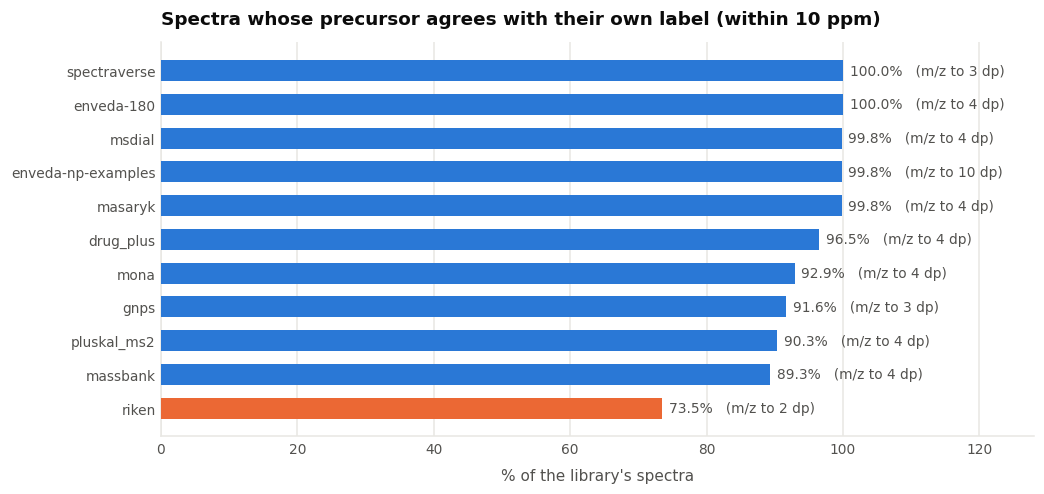

In [26]:
fig, ax = plt.subplots(figsize=(9.6, 4.6))
d = qual.sort_values("pct_within_10ppm")
cols = [ORANGE if ix == "riken" else BLUE for ix in d.index]
ax.barh(range(len(d)), d.pct_within_10ppm, color=cols, height=0.62, zorder=3)
ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index)
for i, (v, dec) in enumerate(zip(d.pct_within_10ppm, d.precursor_decimals_med)):
    ax.text(v + 1, i, f"{v:.1f}%   (m/z to {dec:.0f} dp)", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, 128)
style(ax, title="Spectra whose precursor agrees with their own label (within 10 ppm)",
      xlabel="% of the library's spectra", grid="x")
fig.tight_layout(); plt.show()

### Do not throw `riken` away

`riken` looks like the worst library in the file -- only **73.5%** of its spectra agree with their
own label within 10 ppm, against 100% for `enveda-180`. But the right-hand annotation explains it:
**`riken` reports precursor m/z to a median of two decimal places.** At 350 Da, rounding to
0.01 Da is already 29 ppm of error. The labels are fine; the *precision* is low.

This matters because `riken` is 347k spectra of plant specialised metabolites -- some of the most
test-relevant chemistry in the file. A blanket "drop everything above 10 ppm" filter would delete
a quarter of it for a reason that has nothing to do with correctness. Filter on ppm **per library**,
with a threshold scaled to that library's reported precision.

The libraries genuinely worth scrutinising on ppm are `pluskal_ms2`, `gnps` and `massbank`, which
report 3-4 decimals and still miss.

In [27]:
# duplicates and near-duplicates
dup_key = tr.inchikey14 + "|" + tr.adduct + "|" + tr.precursor_mz.round(3).astype(str) + \
          "|" + tr.num_peaks.astype(str) + "|" + tr.collision_energy_orig.fillna("na")
print(f"exact (structure, adduct, m/z, npeaks, energy) repeats : {dup_key.duplicated().sum():,} "
      f"({dup_key.duplicated().mean()*100:.1f}%)")
print(f"structures whose SMILES differ but InChIKey14 matches  : "
      f"{tr.normalized_smiles.nunique() - tr.inchikey14.nunique():,}  "
      f"(stereoisomers/tautomers collapsing to one answer)")
print(f"\nrows with num_peaks <= 5 (little structural information) : "
      f"{(tr.num_peaks <= 5).sum():,} ({(tr.num_peaks <= 5).mean()*100:.1f}%)")
print(f"rows with num_peaks == 1                                 : {(tr.num_peaks == 1).sum():,}")
print(f"max peaks in a single training spectrum                  : {tr.num_peaks.max():,}")

exact (structure, adduct, m/z, npeaks, energy) repeats : 182,388 (7.2%)
structures whose SMILES differ but InChIKey14 matches  : 1,756  (stereoisomers/tautomers collapsing to one answer)

rows with num_peaks <= 5 (little structural information) : 261,490 (10.3%)
rows with num_peaks == 1                                 : 45,683
max peaks in a single training spectrum                  : 73,318


## 13. Train vs test, and a warning about the public leaderboard

The data page tells you plainly that the test file you can see "is comprised of examples from the
training dataset" and will be swapped for the hidden set at re-run. It is worth knowing **which**
examples, because the answer determines how much the public leaderboard is worth.

We can check without needing any labels: key every test spectrum on
`(adduct, precursor m/z, peak count)`, look the key up in train, and then verify the hit by
comparing the full m/z array element-wise.

In [28]:
def key_of(df):
    return (df.adduct.astype(str) + "|" + df.precursor_mz.round(4).astype(str)
            + "|" + df.num_peaks.astype(str))
tr["_k"] = key_of(tr); te["_k"] = key_of(te)
lut = tr.groupby("_k").agg(n=("_k", "size"),
                           libs=("ingest_lib", lambda s: "/".join(sorted(set(s)))))
m = te[["spectrum_id", "_k"]].merge(lut, left_on="_k", right_index=True, how="left")
print(f"test spectra with an exact (adduct, m/z, peak-count) match in train : "
      f"{m.n.notna().sum():,} / {len(te):,}\n")
print("source library of the matched training rows:")
print(m.libs.value_counts(dropna=False).to_string())

test spectra with an exact (adduct, m/z, peak-count) match in train : 1,213 / 1,213

source library of the matched training rows:
libs
enveda-180                1205
enveda-180/pluskal_ms2       6
enveda-180/gnps              1
enveda-180/riken             1


In [29]:
# verify by full peak-array equality on a sample (needs a second targeted read)
check = m.dropna(subset=["n"]).sample(min(150, int(m.n.notna().sum())), random_state=0)
keys = set(check._k)
hits = collections.defaultdict(list)
for rg in range(pf.metadata.num_row_groups):
    lo, hi = offs[rg], offs[rg+1]
    kk = tr._k.values[lo:hi]
    loc = np.nonzero(np.isin(kk, list(keys)))[0]
    if len(loc) == 0: continue
    tbl = pf.read_row_group(rg, columns=["ms2_mzs"])
    c = tbl.column("ms2_mzs").combine_chunks()
    o, v = c.offsets.to_numpy(), c.values.to_numpy()
    for k in loc:
        hits[kk[k]].append(v[o[k]:o[k+1]])
    del tbl, c, v

exact = 0
for _, r in check.iterrows():
    tmz = np.asarray(te.loc[te.spectrum_id == r.spectrum_id, "ms2_mzs"].iloc[0], float)
    for cmz in hits.get(r._k, []):
        if len(cmz) == len(tmz) and np.allclose(cmz, tmz, atol=1e-6):
            exact += 1; break
print(f"verified element-wise identical peak arrays: {exact} / {len(check)} sampled test spectra")

verified element-wise identical peak arrays: 150 / 150 sampled test spectra


So the public test file is not merely "drawn from train" -- it is **`enveda-180` rows, verbatim**.

That has one consequence worth being blunt about: **the public leaderboard is scoring you on
drug-like synthetic screening compounds that are already in your training file, while the prize is
decided on natural products that are not.** A public score can be driven arbitrarily high by
memorising `enveda-180`, and that number will tell you nothing about the private set. Chasing it
is worse than ignoring it, because it will steer your model toward exactly the wrong chemistry.

What to do instead: build a validation split that resembles the real test set.

1. **Hold out `enveda-np-examples`** (250 structures, test instrument, test pipeline). This is the
   organisers' own bridge between the two domains, and it is the closest thing to a Class-1 dry run.
2. **Split by `inchikey14`, never by row** -- or the 22 copies of a `riken` compound leak across
   the boundary.
3. **Simulate Class 2 by scaffold-holdout**: remove a structure *and every structure sharing its
   Murcko scaffold* from the reference side, then try to retrieve it. That is the only honest way
   to measure whether you can find a molecule with no spectra of its own.

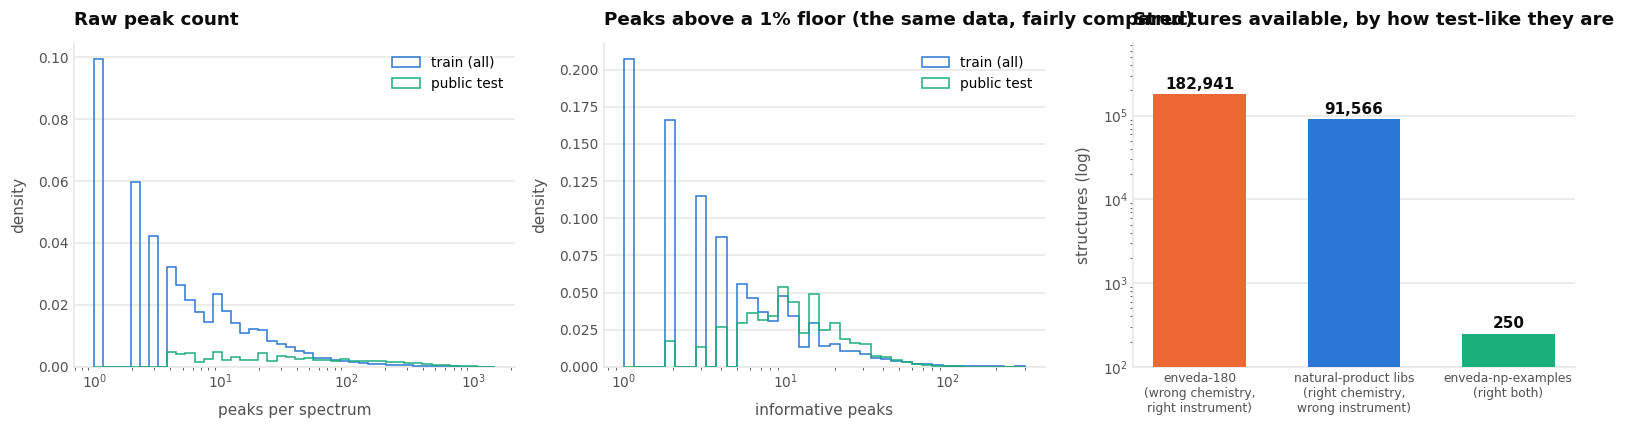

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.0))
tr_np = tr[tr.ingest_lib.isin(np_libs)]

ax = axes[0]
for d, c, lab in [(tr.num_peaks.clip(1, 1500), BLUE, "train (all)"),
                  (pd.Series(pt.n.values).clip(1, 1500), AQUA, "public test")]:
    ax.hist(d, bins=np.logspace(0, np.log10(1500), 45), density=True,
            histtype="step", lw=2, color=c, label=lab, zorder=3)
ax.set_xscale("log")
style(ax, title="Raw peak count", xlabel="peaks per spectrum", ylabel="density", legend=True)

ax = axes[1]
for d, c, lab in [(ps.n_ge_1pct.clip(1, 300), BLUE, "train (all)"),
                  (pt.n_ge_1pct.clip(1, 300), AQUA, "public test")]:
    ax.hist(d, bins=np.logspace(0, np.log10(300), 40), density=True,
            histtype="step", lw=2, color=c, label=lab, zorder=3)
ax.set_xscale("log")
style(ax, title="Peaks above a 1% floor (the same data, fairly compared)",
      xlabel="informative peaks", ylabel="density", legend=True)

ax = axes[2]
lab_counts = [len(m_e180), len(m_np), len(chem[chem.ingest_lib == "enveda-np-examples"])]
labs = ["enveda-180\n(wrong chemistry,\nright instrument)",
        "natural-product libs\n(right chemistry,\nwrong instrument)",
        "enveda-np-examples\n(right both)"]
ax.bar(range(3), lab_counts, color=[ORANGE, BLUE, AQUA], width=0.6, zorder=3)
ax.set_yscale("log"); ax.set_xticks(range(3)); ax.set_xticklabels(labs, fontsize=8)
for i, v in enumerate(lab_counts):
    ax.text(i, v*1.15, f"{v:,}", ha="center", fontsize=10, fontweight="bold", color=INK)
ax.set_ylim(100, max(lab_counts)*4)
style(ax, title="Structures available, by how test-like they are", ylabel="structures (log)")
fig.tight_layout(); plt.show()

## 14. An anchor for the metric: how far does plain library search get you?

MRR@25 is hard to reason about in the abstract, so let us put a floor under it with the simplest
method that exists -- no learning at all.

**Setup.** Query = the 1,151 `enveda-np-examples` spectra (250 natural products, test instrument).
Reference = every other training spectrum. For each query we take candidates within **10 ppm** of
the precursor with the **same adduct**, score them with **modified cosine similarity** (matching
peaks on both the direct and the precursor-shifted axis, sqrt-weighted intensities, 1% floor,
top-64 peaks), take each candidate structure's best score across all of the molecule's spectra,
rank, and compute MRR@25.

This is the honest "Class 1" scenario: the molecule is a natural product and reference spectra for
it exist somewhere in the library.

In [31]:
def prep(mz, it, pmz, thr=0.01, topn=64):
    k = (it >= thr) & (mz <= pmz + 2)
    mz, it = mz[k], it[k]
    if len(mz) > topn:
        o = np.argsort(it)[-topn:]; mz, it = mz[o], it[o]
    o = np.argsort(mz)
    it = np.sqrt(it[o]); nrm = np.linalg.norm(it)
    return mz[o], (it / nrm if nrm > 0 else it)

def modified_cosine(a, b, pa, pb, tol=0.02):
    (ma, ia), (mb, ib) = a, b
    if len(ma) == 0 or len(mb) == 0: return 0.0
    dm = mb[None, :] - ma[:, None]
    cand = []
    for M in (np.abs(dm) <= tol, np.abs(dm - (pb - pa)) <= tol):
        ii, jj = np.nonzero(M)
        if len(ii): cand.append(np.stack([ii, jj, ia[ii] * ib[jj]], 1))
    if not cand: return 0.0
    c = np.concatenate(cand); c = c[np.argsort(-c[:, 2])]
    ua, ub, s = set(), set(), 0.0
    for i, j, v in c:
        i, j = int(i), int(j)
        if i in ua or j in ub: continue
        ua.add(i); ub.add(j); s += v
    return float(s)

t0 = time.time()
gm = tr.set_index("gidx")[["precursor_mz", "inchikey14"]]
prec_of, ik_of = gm.precursor_mz.to_dict(), gm.inchikey14.to_dict()
Rcache, per_mol = {}, {}
for gq, ikq, pq_ in zip(q.gidx.values, q.inchikey14.values, q.precursor_mz.values):
    qa = prep(*PEAKS[gq], pq_)
    d = per_mol.setdefault(ikq, {})
    for g in cand_map[gq]:
        if g not in Rcache:
            Rcache[g] = prep(*PEAKS[g], prec_of[g])
        s = modified_cosine(qa, Rcache[g], pq_, prec_of[g])
        ik = ik_of[g]
        if s > d.get(ik, 0.0): d[ik] = s

rr, top1, top25 = [], 0, 0
for ik, d in per_mol.items():
    ranked = sorted(d.items(), key=lambda kv: -kv[1])[:25]
    pos = next((i + 1 for i, (k, _) in enumerate(ranked) if k == ik), None)
    rr.append(1.0 / pos if pos else 0.0)
    top1 += (pos == 1); top25 += (pos is not None)
N = len(per_mol)
print(f"scored in {time.time()-t0:.1f}s\n")
print(f"  molecules evaluated            {N}")
print(f"  median candidates per molecule {np.median([len(d) for d in per_mol.values()]):.0f}")
print(f"  ---------------------------------------")
print(f"  MRR@25                         {np.mean(rr):.4f}")
print(f"  correct at rank 1              {top1/N*100:.1f}%")
print(f"  correct somewhere in top 25    {top25/N*100:.1f}%")

scored in 27.8s

  molecules evaluated            250
  median candidates per molecule 11
  ---------------------------------------
  MRR@25                         0.9090
  correct at rank 1              85.6%
  correct somewhere in top 25    98.8%


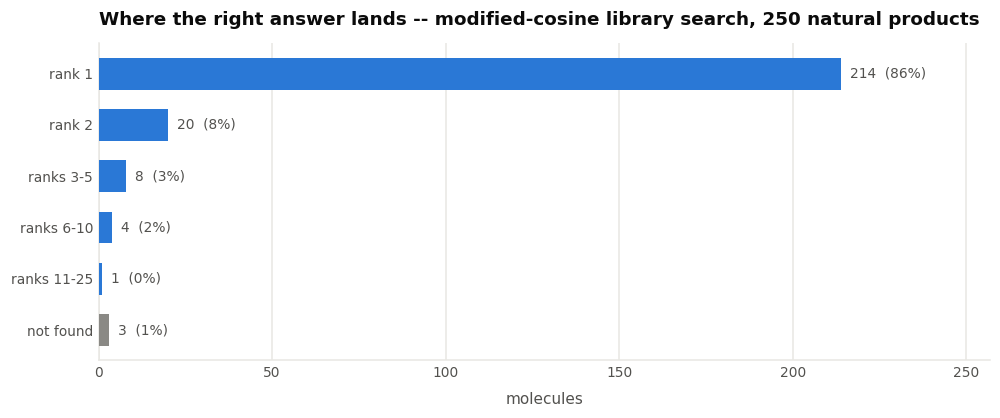

In [32]:
fig, ax = plt.subplots(figsize=(9.2, 3.9))
ranks = []
for ik, d in per_mol.items():
    ranked = sorted(d.items(), key=lambda kv: -kv[1])[:25]
    pos = next((i + 1 for i, (k, _) in enumerate(ranked) if k == ik), 26)
    ranks.append(pos)
ranks = np.array(ranks)
bins = [1, 2, 3, 6, 11, 26, 27]
labs = ["rank 1", "rank 2", "ranks 3-5", "ranks 6-10", "ranks 11-25", "not found"]
h = [((ranks >= bins[i]) & (ranks < bins[i+1])).sum() for i in range(len(labs))]
cols = [BLUE]*5 + [INK3]
ax.barh(range(len(labs)), h, color=cols, height=0.62, zorder=3)
ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs); ax.invert_yaxis()
for i, v in enumerate(h):
    ax.text(v + max(h)*0.012, i, f"{v}  ({v/N*100:.0f}%)", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, max(h)*1.2)
style(ax, title="Where the right answer lands -- modified-cosine library search, 250 natural products",
      xlabel="molecules", grid="x")
fig.tight_layout(); plt.show()

**MRR@25 ~ 0.91, with 85% correct at rank 1.**

That number is the most useful thing in this notebook, because of what it implies about where the
competition is actually decided:

* **Novelty Class 1** (the structure has public reference spectra) is close to solved by a
  90-line library search. A neural model that does not clearly beat 0.91 here is not earning its
  complexity.
* Therefore **your entire score differential lives in Classes 2 and 3** -- molecules with no
  reference spectra at all, where similarity to the training library cannot help you and you must
  retrieve from PubChem/COCONUT or generate structures outright.
* The class mix is hidden for the duration of the competition, which means you cannot tune to it.
  The robust play is a **cascade**: library search for the easy ones, database retrieval with a
  learned spectrum-to-structure scorer for Class 2, de novo generation for Class 3 -- with a
  calibrated way to decide which branch each molecule gets, and 25 slots to hedge across branches.

Remember that a wrong guess costs nothing. **Always submit all 25 candidates** -- an unfilled
slot is score you have simply declined to collect.

## 15. An optional look at the structures themselves

Everything above was done from formulas, so the notebook runs without RDKit. If RDKit is
available, here is the chemistry it adds -- scaffolds and a look at the most heavily measured
compounds in the file.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 48.0 MB/s eta 0:00:00


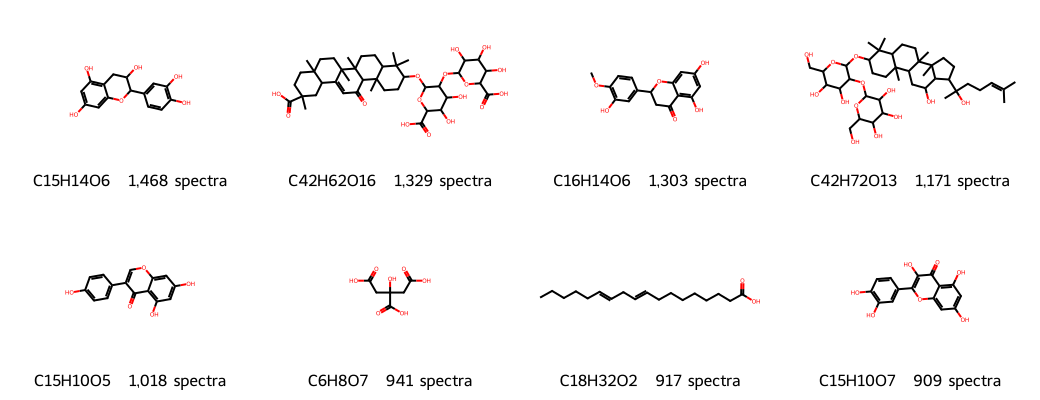


Murcko scaffolds in a 25,000-structure sample: 18,062 distinct
  structures per scaffold: median 1, max 1,242
  singleton scaffolds    : 15,978 (88.5%)

  A scaffold-aware holdout is the right way to simulate novelty Class 2.


In [33]:
try:
    try:
        import rdkit
    except ImportError:            # not in the Kaggle image; needs internet enabled
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rdkit"], check=True)
    from rdkit import Chem, RDLogger
    from rdkit.Chem import Draw, Descriptors
    from rdkit.Chem.Scaffolds import MurckoScaffold
    RDLogger.DisableLog("rdApp.*")

    top = tr.groupby("inchikey14").size().sort_values(ascending=False).head(8)
    smis = [tr.loc[tr.inchikey14 == k, "normalized_smiles"].iloc[0] for k in top.index]
    mols = [Chem.MolFromSmiles(s) for s in smis]
    forms = [tr.loc[tr.inchikey14 == k, "molecular_formula"].iloc[0] for k in top.index]
    legends = [f"{f}   {v:,} spectra" for f, v in zip(forms, top.values)]
    display(Draw.MolsToGridImage([m for m in mols if m], molsPerRow=4,
                                 subImgSize=(260, 200), legends=legends))

    samp = uni.sample(min(25000, len(uni)), random_state=3)
    scafs = []
    for s in samp.normalized_smiles:
        m = Chem.MolFromSmiles(s)
        if m is None: continue
        try: scafs.append(MurckoScaffold.MurckoScaffoldSmiles(mol=m))
        except Exception: pass
    sc = pd.Series(scafs).value_counts()
    print(f"\nMurcko scaffolds in a {len(scafs):,}-structure sample: {len(sc):,} distinct")
    print(f"  structures per scaffold: median {sc.median():.0f}, max {sc.max():,}")
    print(f"  singleton scaffolds    : {(sc==1).sum():,} ({(sc==1).mean()*100:.1f}%)")
    print("\n  A scaffold-aware holdout is the right way to simulate novelty Class 2.")
except Exception as exc:
    print(f"RDKit unavailable ({type(exc).__name__}) -- skipping this section.")
    print("Everything above this cell is computed from molecular_formula and needs no RDKit.")

## 16. Takeaways

A checklist, in rough order of how much score each one is worth.

**Preprocessing**
1. **Apply a relative-intensity floor (~1%) before anything else.** It removes most of the
   apparent train/test mismatch, because that mismatch is noise floor, not chemistry.
2. **Drop peaks above precursor + 2 Da in train.** The test set has had them removed; `riken`
   and `gnps` still carry them at 11% and 3%.
3. **Consider dropping the 14.3% of rows on adducts that cannot occur in test** (`[2M+...]`
   dimers and friends), or at least feature-flag them.
4. **Use `collision_energy_ev`**, and give the model an explicit path for the 13% with no
   usable energy.

**Validation -- this is where most people will lose the competition**

5. **Ignore the public leaderboard.** It is `enveda-180` rows verbatim: the wrong chemistry,
   already in your training file.
6. **Split on `inchikey14`, never on rows.** `riken` measures a compound 22 times on average.
7. **Hold out `enveda-np-examples`** as your Class-1 dry run: it is the only data that is both
   instrument-matched and chemistry-matched.
8. **Use scaffold-holdout to simulate Class 2.** Removing a structure without removing its
   scaffold neighbours measures nothing.
9. **Filter `precursor_error_ppm` per library, not globally** -- `riken`'s large errors are
   2-decimal rounding, not bad labels, and it is 347k spectra of exactly the chemistry you want.

**Modelling**

10. **Aggregate per molecule, not per spectrum.** Each test molecule brings a positive/negative
    pair and an energy ladder; that is complementary evidence, and the metric is per molecule.
11. **A formula is not an answer** -- median 20 training isomers share it, and vastly more in
    PubChem. Ranking inside the candidate list is the whole game.
12. **Beat 0.91 on Class-1-like molecules before adding complexity**, then spend everything else
    on Classes 2 and 3, which is where the differential actually is.
13. **Always fill all 25 slots.** Wrong guesses are free.

---

*Data: Enveda CASMI 2026, CC BY-NC 4.0. If this was useful, an upvote is appreciated -- and
corrections are very welcome in the comments.*